In [176]:
# ============================================================
# IDENTITAS PROYEK
# ============================================================

NAMA_PROYEK = "Klasifikasi Kondisi Gelombang Laut"
NAMA_MAHASISWA = "Putri Fadhilah Zuhairah"
NIM = "ISI_NIM"
EMAIL = "ISI_EMAIL"

print("Nama proyek:", NAMA_PROYEK)
print("Nama mahasiswa:", NAMA_MAHASISWA)
print("NIM:", NIM)
print("Email:", EMAIL)

Nama proyek: Klasifikasi Kondisi Gelombang Laut
Nama mahasiswa: Putri Fadhilah Zuhairah
NIM: ISI_NIM
Email: ISI_EMAIL


In [177]:
# ============================================================
# PERTANYAAN BISNIS
# ============================================================

business_questions = {

    "BQ1": """
    Bagaimana kondisi gelombang laut pada masing-masing wilayah
    perairan berdasarkan data cuaca dan kondisi laut?
    """,

    "BQ2": """
    Bagaimana hubungan antara kecepatan angin, tinggi gelombang,
    dan kecepatan arus terhadap kategori kondisi gelombang laut?
    """,

    "BQ3": """
    Bagaimana perbedaan kondisi gelombang laut berdasarkan lokasi
    wilayah perairan dan waktu pengamatan?
    """,

    "BQ4": """
    Dapatkah kondisi gelombang laut diklasifikasikan menjadi kategori
    Tenang dan Rendah berdasarkan faktor cuaca, kondisi laut, lokasi,
    waktu, dan aktivitas gempa?
    """
}

In [178]:
%pip install pandas numpy matplotlib seaborn mysql-connector-python scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [179]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\Hype GLK\AppData\Local\Python\pythoncore-3.14-64\python.exe
3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]


In [180]:
# ============================================================
# IMPORT LIBRARY
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import mysql.connector

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [181]:
# ============================================================
# TAMPILAN AWAL
# ============================================================

print("\n" + "=" * 80)
print("PROYEK:", NAMA_PROYEK)
print("NAMA  :", NAMA_MAHASISWA)
print("NIM   :", NIM)
print("EMAIL :", EMAIL)
print("=" * 80)

print("\nPERTANYAAN BISNIS")
print("-" * 80)

for kode, pertanyaan in business_questions.items():
    print(f"\n{kode}: {pertanyaan.strip()}")




PROYEK: Klasifikasi Kondisi Gelombang Laut
NAMA  : Putri Fadhilah Zuhairah
NIM   : ISI_NIM
EMAIL : ISI_EMAIL

PERTANYAAN BISNIS
--------------------------------------------------------------------------------

BQ1: Bagaimana kondisi gelombang laut pada masing-masing wilayah
    perairan berdasarkan data cuaca dan kondisi laut?

BQ2: Bagaimana hubungan antara kecepatan angin, tinggi gelombang,
    dan kecepatan arus terhadap kategori kondisi gelombang laut?

BQ3: Bagaimana perbedaan kondisi gelombang laut berdasarkan lokasi
    wilayah perairan dan waktu pengamatan?

BQ4: Dapatkah kondisi gelombang laut diklasifikasikan menjadi kategori
    Tenang dan Rendah berdasarkan faktor cuaca, kondisi laut, lokasi,
    waktu, dan aktivitas gempa?


In [182]:
# ============================================================
# 1. GATHERING DATA DARI DATABASE MYSQL
# ============================================================

print("\n" + "=" * 80)
print("1. GATHERING DATA DARI DATABASE MYSQL")
print("=" * 80)

conn = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="root",
    password="root",
    database="airflow_db"
)

# ------------------------------------------------------------
# 1.1 DATA CUACA
# ------------------------------------------------------------

query_cuaca = """
SELECT *
FROM marine_data_cuaca
"""

df_cuaca = pd.read_sql(query_cuaca, conn)

print("\n[1] DATA CUACA")
print("Jumlah baris :", len(df_cuaca))
print("Jumlah kolom :", len(df_cuaca.columns))

print("\nKolom:")
print(df_cuaca.columns.tolist())

print("\nContoh data:")
print(df_cuaca.head())

# ------------------------------------------------------------
# 1.2 DATA KONDISI LAUT
# ------------------------------------------------------------

query_utama = """
SELECT *
FROM marine_data_utama
"""

df_utama = pd.read_sql(query_utama, conn)

print("\n[2] DATA KONDISI LAUT")
print("Jumlah baris :", len(df_utama))
print("Jumlah kolom :", len(df_utama.columns))

print("\nKolom:")
print(df_utama.columns.tolist())

print("\nContoh data:")
print(df_utama.head())

# ------------------------------------------------------------
# 1.3 DATA GEMPA
# ------------------------------------------------------------

query_gempa = """
SELECT *
FROM marine_data_gempa
"""

df_gempa = pd.read_sql(query_gempa, conn)

print("\n[3] DATA GEMPA")
print("Jumlah baris :", len(df_gempa))
print("Jumlah kolom :", len(df_gempa.columns))

print("\nKolom:")
print(df_gempa.columns.tolist())

print("\nContoh data:")
print(df_gempa.head())


conn.close()

# ============================================================
# INSIGHT GATHERING DATA - OTOMATIS
# ============================================================

jumlah_cuaca = len(df_cuaca)
jumlah_kolom_cuaca = len(df_cuaca.columns)

jumlah_laut = len(df_utama)
jumlah_kolom_laut = len(df_utama.columns)

jumlah_gempa = len(df_gempa)
jumlah_kolom_gempa = len(df_gempa.columns)

print("\n" + "=" * 80)
print("INSIGHT GATHERING DATA")
print("=" * 80)

print(f"""
Data berhasil dikumpulkan dari tiga sumber utama, yaitu data cuaca,
data kondisi laut, dan data gempa.

Data cuaca terdiri dari {jumlah_cuaca:,} baris dan {jumlah_kolom_cuaca}
kolom. Data kondisi laut terdiri dari {jumlah_laut:,} baris dan
{jumlah_kolom_laut} kolom. Sementara itu, data gempa terdiri dari
{jumlah_gempa:,} baris dan {jumlah_kolom_gempa} kolom.

Ketiga dataset tersebut digunakan sebagai sumber data untuk
menganalisis kondisi gelombang laut serta faktor-faktor yang
berkaitan dengannya.
""")


1. GATHERING DATA DARI DATABASE MYSQL


C:\Users\Hype GLK\AppData\Local\Temp\ipykernel_17100\3774439080.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_cuaca = pd.read_sql(query_cuaca, conn)



[1] DATA CUACA
Jumlah baris : 641
Jumlah kolom : 12

Kolom:
['cuaca_id', 'adm4', 'location_name', 'related_area', 'forecast_time', 'utc_datetime', 'weather', 'temperature', 'humidity', 'wind_speed', 'visibility', 'created_at']

Contoh data:
   cuaca_id           adm4 location_name related_area       forecast_time  \
0         1  74.14.01.2001     Pasarwajo        Buton 2026-09-29 22:00:00   
1         2  74.14.01.2001     Pasarwajo        Buton 2026-09-30 01:00:00   
2         3  74.14.01.2001     Pasarwajo        Buton 2026-09-30 04:00:00   
3         4  74.14.01.2001     Pasarwajo        Buton 2026-09-30 07:00:00   
4         5  74.14.01.2001     Pasarwajo        Buton 2026-09-30 10:00:00   

         utc_datetime        weather  temperature  humidity  wind_speed  \
0 2026-09-29 14:00:00        Berawan         24.0      89.0         5.1   
1 2026-09-29 17:00:00          Cerah         23.0      96.0         3.8   
2 2026-09-29 20:00:00  Cerah Berawan         22.0      98.0         2.

C:\Users\Hype GLK\AppData\Local\Temp\ipykernel_17100\3774439080.py:47: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_utama = pd.read_sql(query_utama, conn)



[2] DATA KONDISI LAUT
Jumlah baris : 5313
Jumlah kolom : 18

Kolom:
['forecast_id', 'area_id', 'area_name', 'forecast_time', 'weather', 'temperature', 'humidity', 'wind_direction', 'wind_speed', 'wind_gust', 'wave_category', 'wave_height', 'current_direction', 'current_speed', 'issued_at', 'valid_from', 'valid_to', 'created_at']

Contoh data:
   forecast_id  area_id       area_name       forecast_time        weather  \
0          124  P.AF.01  Selat Labengki 2026-09-29 00:00:00  Berawan Tebal   
1          125  P.AF.01  Selat Labengki 2026-09-29 01:00:00  Berawan Tebal   
2          126  P.AF.01  Selat Labengki 2026-09-29 02:00:00        Berawan   
3          127  P.AF.01  Selat Labengki 2026-09-29 03:00:00  Cerah Berawan   
4          128  P.AF.01  Selat Labengki 2026-09-29 04:00:00        Berawan   

   temperature  humidity wind_direction  wind_speed  wind_gust wave_category  \
0         26.0      84.0          Utara         2.0        9.0        Tenang   
1         26.0      80.0 

C:\Users\Hype GLK\AppData\Local\Temp\ipykernel_17100\3774439080.py:68: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_gempa = pd.read_sql(query_gempa, conn)



[3] DATA GEMPA
Jumlah baris : 54
Jumlah kolom : 14

Kolom:
['gempa_id', 'source', 'tanggal', 'jam', 'datetime_gempa', 'magnitude', 'kedalaman_km', 'latitude', 'longitude', 'wilayah', 'potensi', 'dirasakan', 'shakemap', 'created_at']

Contoh data:
   gempa_id source      tanggal           jam      datetime_gempa  magnitude  \
0         1   felt  28 Sep 2026  21:43:09 WIB 2026-09-28 14:43:09        4.5   
1         2     m5  22 Sep 2026  06:48:13 WIB 2026-09-21 23:48:13        5.2   
2         3     m5  21 Sep 2026  14:31:07 WIB 2026-09-21 07:31:07        5.3   
3         4     m5  21 Sep 2026  08:41:37 WIB 2026-09-21 01:41:37        5.3   
4         5     m5  19 Sep 2026  11:18:36 WIB 2026-09-19 04:18:36        5.1   

   kedalaman_km  latitude  longitude  \
0          10.0      5.19      94.41   
1          10.0      4.74     125.30   
2          10.0     -0.70     122.45   
3          10.0     -8.33     120.59   
4          10.0     -1.60     138.88   

                              

In [183]:
# ============================================================
# 2. ASSESSING DATA SEBELUM CLEANING
# ============================================================

print("\n" + "=" * 80)
print("2. ASSESSING DATA SEBELUM CLEANING")
print("=" * 80)

# ------------------------------------------------------------
# 2.1 ASSESSING DATA CUACA
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("ASSESSING DATA CUACA")
print("-" * 80)

print("\n--- INFO DATA ---")
df_cuaca.info()

print("\n--- STATISTIK DESKRIPTIF ---")
print(df_cuaca.describe(include="all"))

print("\n--- MISSING VALUES ---")
print(df_cuaca.isnull().sum())

print("\n--- JUMLAH DUPLIKAT ---")
print(df_cuaca.duplicated().sum())

print("\n--- 5 DATA PERTAMA ---")
print(df_cuaca.head())

# ------------------------------------------------------------
# 2.2 ASSESSING DATA KONDISI LAUT
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("ASSESSING DATA KONDISI LAUT")
print("-" * 80)

print("\n--- INFO DATA ---")
df_utama.info()

print("\n--- STATISTIK DESKRIPTIF ---")
print(df_utama.describe(include="all"))

print("\n--- MISSING VALUES ---")
print(df_utama.isnull().sum())

print("\n--- JUMLAH DUPLIKAT ---")
print(df_utama.duplicated().sum())

print("\n--- 5 DATA PERTAMA ---")
print(df_utama.head())

# ------------------------------------------------------------
# 2.3 ASSESSING DATA GEMPA
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("ASSESSING DATA GEMPA")
print("-" * 80)

print("\n--- INFO DATA ---")
df_gempa.info()

print("\n--- STATISTIK DESKRIPTIF ---")
print(df_gempa.describe(include="all"))

print("\n--- MISSING VALUES ---")
print(df_gempa.isnull().sum())

print("\n--- JUMLAH DUPLIKAT ---")
print(df_gempa.duplicated().sum())

print("\n--- 5 DATA PERTAMA ---")
print(df_gempa.head())

# ============================================================
# INSIGHT ASSESSING DATA SEBELUM CLEANING - OTOMATIS
# ============================================================

dataset = {
    "Data Cuaca": df_cuaca,
    "Data Kondisi Laut": df_utama,
    "Data Gempa": df_gempa
}

print("\n" + "=" * 80)
print("INSIGHT ASSESSING DATA SEBELUM CLEANING")
print("=" * 80)

for nama, data in dataset.items():

    jumlah_baris = len(data)
    jumlah_kolom = len(data.columns)
    jumlah_missing = data.isnull().sum().sum()
    jumlah_duplikat = data.duplicated().sum()

    print(f"""
{nama}
- Jumlah data       : {jumlah_baris:,}
- Jumlah kolom      : {jumlah_kolom}
- Total missing     : {jumlah_missing:,}
- Data duplikat     : {jumlah_duplikat:,}
""")

# ------------------------------------------------------------
# MISSING VALUE PER KOLOM
# ------------------------------------------------------------

print("\n--- KOLOM DENGAN MISSING VALUE ---")

for nama, data in dataset.items():

    missing = data.isnull().sum()
    missing = missing[missing > 0]

    print(f"\n{nama}:")

    if len(missing) == 0:
        print("Tidak terdapat missing value.")
    else:
        for kolom, jumlah in missing.items():
            persentase = (jumlah / len(data)) * 100

            print(
                f"- {kolom}: {jumlah:,} data "
                f"({persentase:.2f}%)"
            )

# ------------------------------------------------------------
# INSIGHT OTOMATIS
# ------------------------------------------------------------

print("\n--- KESIMPULAN ASSESSING ---")

print("""
Hasil assessment menunjukkan bahwa ketiga dataset memiliki
karakteristik dan permasalahan kualitas data yang berbeda.
Pemeriksaan jumlah data, missing value, dan duplikasi dilakukan
sebagai dasar untuk menentukan penanganan data pada tahap cleaning.
Kolom yang memiliki missing value akan dipertimbangkan berdasarkan
kebutuhan analisis dan penggunaan variabel pada tahap berikutnya.
""")


2. ASSESSING DATA SEBELUM CLEANING

--------------------------------------------------------------------------------
ASSESSING DATA CUACA
--------------------------------------------------------------------------------

--- INFO DATA ---
<class 'pandas.DataFrame'>
RangeIndex: 641 entries, 0 to 640
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   cuaca_id       641 non-null    int64         
 1   adm4           641 non-null    str           
 2   location_name  641 non-null    str           
 3   related_area   641 non-null    str           
 4   forecast_time  641 non-null    datetime64[us]
 5   utc_datetime   641 non-null    datetime64[us]
 6   weather        641 non-null    str           
 7   temperature    641 non-null    float64       
 8   humidity       641 non-null    float64       
 9   wind_speed     641 non-null    float64       
 10  visibility     0 non-null      object        
 11 

In [184]:
# ============================================================
# 3. CLEANING DATA SUMBER
# ============================================================

print("\n" + "=" * 80)
print("3. CLEANING DATA SUMBER")
print("=" * 80)


# ------------------------------------------------------------
# 3.1 CLEANING DATA CUACA
# ------------------------------------------------------------

print("\n[1] CLEANING DATA CUACA")

print("Data sebelum cleaning:", df_cuaca.shape)

df_cuaca = df_cuaca.drop_duplicates()

df_cuaca["forecast_time"] = pd.to_datetime(
    df_cuaca["forecast_time"],
    errors="coerce"
)

df_cuaca["utc_datetime"] = pd.to_datetime(
    df_cuaca["utc_datetime"],
    errors="coerce"
)

fitur_cuaca = [
    "temperature",
    "humidity",
    "wind_speed"
]

for kolom in fitur_cuaca:
    df_cuaca[kolom] = pd.to_numeric(
        df_cuaca[kolom],
        errors="coerce"
    )

df_cuaca = df_cuaca.dropna(
    subset=["forecast_time"]
)

print("Data setelah cleaning:", df_cuaca.shape)


# ------------------------------------------------------------
# 3.2 CLEANING DATA KONDISI LAUT
# ------------------------------------------------------------

print("\n[2] CLEANING DATA KONDISI LAUT")

print("Data sebelum cleaning:", df_utama.shape)

df_utama = df_utama.drop_duplicates()

df_utama["forecast_time"] = pd.to_datetime(
    df_utama["forecast_time"],
    errors="coerce"
)

fitur_laut = [
    "temperature",
    "humidity",
    "wind_speed",
    "wind_gust",
    "wave_height",
    "current_speed"
]

for kolom in fitur_laut:
    df_utama[kolom] = pd.to_numeric(
        df_utama[kolom],
        errors="coerce"
    )

df_utama = df_utama.dropna(
    subset=[
        "forecast_time",
        "wave_category"
    ]
)

print("Data setelah cleaning:", df_utama.shape)


# ------------------------------------------------------------
# 3.3 CLEANING DATA GEMPA
# ------------------------------------------------------------

print("\n[3] CLEANING DATA GEMPA")

print("Data sebelum cleaning:", df_gempa.shape)

df_gempa = df_gempa.drop_duplicates()

df_gempa["datetime_gempa"] = pd.to_datetime(
    df_gempa["datetime_gempa"],
    errors="coerce"
)

fitur_gempa = [
    "magnitude",
    "kedalaman_km",
    "latitude",
    "longitude"
]

for kolom in fitur_gempa:
    df_gempa[kolom] = pd.to_numeric(
        df_gempa[kolom],
        errors="coerce"
    )

df_gempa = df_gempa.dropna(
    subset=["datetime_gempa"]
)

print("Data setelah cleaning:", df_gempa.shape)

# ============================================================
# INSIGHT CLEANING DATA SUMBER
# ============================================================

dataset = {
    "Data Cuaca": df_cuaca,
    "Data Kondisi Laut": df_utama,
    "Data Gempa": df_gempa
}

print("\n" + "=" * 80)
print("INSIGHT CLEANING DATA SUMBER")
print("=" * 80)

for nama, data in dataset.items():

    jumlah_baris = len(data)
    jumlah_kolom = len(data.columns)
    jumlah_missing = data.isnull().sum().sum()
    jumlah_duplikat = data.duplicated().sum()

    print(f"""
{nama}
- Jumlah data setelah cleaning : {jumlah_baris:,}
- Jumlah kolom                : {jumlah_kolom}
- Total missing value         : {jumlah_missing:,}
- Data duplikat               : {jumlah_duplikat:,}
""")

print("""
Hasil cleaning menunjukkan bahwa ketiga dataset telah melalui
penanganan data duplikat, penyesuaian format tanggal dan waktu,
serta penyesuaian tipe data pada variabel numerik. Data yang tidak
memiliki informasi penting untuk proses analisis juga ditangani
sesuai kebutuhan masing-masing dataset. Dataset hasil cleaning
selanjutnya digunakan pada tahap assessment dan data wrangling.
""")


3. CLEANING DATA SUMBER

[1] CLEANING DATA CUACA
Data sebelum cleaning: (641, 12)


Data setelah cleaning: (641, 12)

[2] CLEANING DATA KONDISI LAUT
Data sebelum cleaning: (5313, 18)
Data setelah cleaning: (5313, 18)

[3] CLEANING DATA GEMPA
Data sebelum cleaning: (54, 14)
Data setelah cleaning: (54, 14)

INSIGHT CLEANING DATA SUMBER

Data Cuaca
- Jumlah data setelah cleaning : 641
- Jumlah kolom                : 12
- Total missing value         : 641
- Data duplikat               : 0


Data Kondisi Laut
- Jumlah data setelah cleaning : 5,313
- Jumlah kolom                : 18
- Total missing value         : 448
- Data duplikat               : 0


Data Gempa
- Jumlah data setelah cleaning : 54
- Jumlah kolom                : 14
- Total missing value         : 108
- Data duplikat               : 0


Hasil cleaning menunjukkan bahwa ketiga dataset telah melalui
penanganan data duplikat, penyesuaian format tanggal dan waktu,
serta penyesuaian tipe data pada variabel numerik. Data yang tidak
memiliki informasi penting untuk proses analisis juga ditangani
sesuai kebutuhan 

In [185]:
# ============================================================
# 4. ASSESSING SETELAH CLEANING
# ============================================================

print("\n" + "=" * 80)
print("4. ASSESSING DATA SETELAH CLEANING")
print("=" * 80)


# ------------------------------------------------------------
# 4.1 DATA CUACA
# ------------------------------------------------------------

print("\n--- DATA CUACA SETELAH CLEANING ---")

print("\nMissing values:")
print(df_cuaca.isnull().sum())

print("\nDuplikat:")
print(df_cuaca.duplicated().sum())

print("\nStatistik deskriptif:")
print(df_cuaca.describe(include="all"))


# ------------------------------------------------------------
# 4.2 DATA KONDISI LAUT
# ------------------------------------------------------------

print("\n--- DATA KONDISI LAUT SETELAH CLEANING ---")

print("\nMissing values:")
print(df_utama.isnull().sum())

print("\nDuplikat:")
print(df_utama.duplicated().sum())

print("\nStatistik deskriptif:")
print(df_utama.describe(include="all"))


# ------------------------------------------------------------
# 4.3 DATA GEMPA
# ------------------------------------------------------------

print("\n--- DATA GEMPA SETELAH CLEANING ---")

print("\nMissing values:")
print(df_gempa.isnull().sum())

print("\nDuplikat:")
print(df_gempa.duplicated().sum())

print("\nStatistik deskriptif:")
print(df_gempa.describe(include="all"))

print("\n" + "=" * 80)
print("INSIGHT ASSESSING DATA SETELAH CLEANING")
print("=" * 80)

dataset = {
    "Data Cuaca": df_cuaca,
    "Data Kondisi Laut": df_utama,
    "Data Gempa": df_gempa
}

print("\n--- RINGKASAN HASIL ASSESSING ---")

for nama, data in dataset.items():

    jumlah_data = len(data)
    jumlah_missing = data.isnull().sum().sum()
    jumlah_duplikat = data.duplicated().sum()

    print(f"""
{nama}
- Jumlah data        : {jumlah_data:,}
- Total missing      : {jumlah_missing:,}
- Total duplikat     : {jumlah_duplikat:,}
""")

print("\n--- KOLOM YANG MASIH MEMILIKI MISSING VALUE ---")

for nama, data in dataset.items():

    missing = data.isnull().sum()
    missing = missing[missing > 0]

    print(f"\n{nama}:")

    if len(missing) == 0:
        print("- Tidak terdapat missing value.")

    else:
        for kolom, jumlah in missing.items():
            persentase = (jumlah / len(data)) * 100

            print(
                f"- {kolom}: {jumlah:,} data "
                f"({persentase:.2f}%)"
            )

print("\n--- KESIMPULAN ---")

semua_duplikat_nol = all(
    data.duplicated().sum() == 0
    for data in dataset.values()
)

if semua_duplikat_nol:
    print("- Tidak ditemukan data duplikat pada ketiga dataset.")
else:
    print("- Masih terdapat data duplikat pada salah satu dataset.")

total_missing = sum(
    data.isnull().sum().sum()
    for data in dataset.values()
)

print(f"- Total missing value yang masih ditemukan: {total_missing:,}")

print("""
Hasil assessing setelah cleaning menunjukkan bahwa data duplikat
telah ditangani dan format variabel yang digunakan dalam analisis
telah disesuaikan. Beberapa missing value masih ditemukan pada
kolom tertentu yang tidak menjadi variabel utama dalam analisis.
Oleh karena itu, missing value tersebut tidak digunakan apabila
kolom terkait tidak diperlukan pada tahap data wrangling dan
analisis selanjutnya.
""")


4. ASSESSING DATA SETELAH CLEANING

--- DATA CUACA SETELAH CLEANING ---

Missing values:
cuaca_id           0
adm4               0
location_name      0
related_area       0
forecast_time      0
utc_datetime       0
weather            0
temperature        0
humidity           0
wind_speed         0
visibility       641
created_at         0
dtype: int64

Duplikat:
0

Statistik deskriptif:
           cuaca_id           adm4 location_name      related_area  \
count    641.000000            641           641               641   
unique          NaN              5             5                 5   
top             NaN  74.10.01.2001       Langara  Konawe Kepulauan   
freq            NaN            133           133               133   
mean     819.285491            NaN           NaN               NaN   
min        1.000000            NaN           NaN               NaN   
25%      262.000000            NaN           NaN               NaN   
50%     1026.000000            NaN           NaN 

In [186]:
# ============================================================
# 5. MENGAMBIL DATASET GABUNGAN YANG SUDAH ADA
# ============================================================

print("\n" + "=" * 80)
print("5. DATASET GABUNGAN HASIL DATA WRANGLING")
print("=" * 80)

conn = mysql.connector.connect(
    host="localhost",
    port=3306,
    user="root",
    password="root",
    database="airflow_db"
)

query_gabungan = """
SELECT
    forecast_id,
    area_id,
    area_name,
    forecast_time,
    latitude,
    longitude,
    temperature,
    humidity,
    wind_speed,
    wind_gust,
    wave_height,
    current_speed,
    wave_category,
    jumlah_gempa_24jam,
    magnitude_maks_24jam,
    jarak_gempa_terdekat_km
FROM dataset_gabungan_gempa
ORDER BY forecast_time
"""

df = pd.read_sql(
    query_gabungan,
    conn
)

conn.close()

print("\nUkuran dataset gabungan:", df.shape)

print("\nKolom dataset gabungan:")
print(df.columns.tolist())

print("\n5 data pertama:")
print(df.head().to_string(index=False))

# ============================================================
# INSIGHT DATASET GABUNGAN HASIL DATA WRANGLING - OTOMATIS
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT DATASET GABUNGAN HASIL DATA WRANGLING")
print("=" * 80)

jumlah_data = len(df)
jumlah_kolom = len(df.columns)
jumlah_wilayah = df["area_name"].nunique()
jumlah_missing = df.isnull().sum().sum()
jumlah_duplikat = df.duplicated().sum()

waktu_awal = df["forecast_time"].min()
waktu_akhir = df["forecast_time"].max()

jumlah_kategori = df["wave_category"].nunique()
kategori_dominan = df["wave_category"].value_counts().idxmax()
jumlah_dominan = df["wave_category"].value_counts().max()

print(f"""
Hasil data wrangling menghasilkan dataset gabungan sebanyak
{jumlah_data:,} data dengan {jumlah_kolom} variabel yang mencakup
{jumlah_wilayah} wilayah perairan.

Dataset mencakup periode pengamatan dari {waktu_awal} hingga
{waktu_akhir}. Data gabungan berisi informasi lokasi, waktu,
cuaca, kondisi laut, kategori gelombang, serta aktivitas gempa.

Dataset memiliki {jumlah_kategori} kategori kondisi gelombang.
Kategori yang paling banyak ditemukan adalah {kategori_dominan}
sebanyak {jumlah_dominan:,} data.

Hasil pemeriksaan juga menunjukkan terdapat {jumlah_missing:,}
missing value dan {jumlah_duplikat:,} data duplikat pada dataset
gabungan.
""")


5. DATASET GABUNGAN HASIL DATA WRANGLING


C:\Users\Hype GLK\AppData\Local\Temp\ipykernel_17100\3502816924.py:39: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(



Ukuran dataset gabungan: (287, 16)

Kolom dataset gabungan:
['forecast_id', 'area_id', 'area_name', 'forecast_time', 'latitude', 'longitude', 'temperature', 'humidity', 'wind_speed', 'wind_gust', 'wave_height', 'current_speed', 'wave_category', 'jumlah_gempa_24jam', 'magnitude_maks_24jam', 'jarak_gempa_terdekat_km']

5 data pertama:
 forecast_id area_id              area_name forecast_time  latitude  longitude  temperature  humidity  wind_speed  wind_gust  wave_height  current_speed wave_category  jumlah_gempa_24jam  magnitude_maks_24jam  jarak_gempa_terdekat_km
         124 P.AF.01         Selat Labengki    2026-09-29     -3.40     122.45         26.0      84.0         2.0        9.0          0.4           0.67        Tenang                   3                   4.5               560.210017
         165 P.AF.02          Laut Labengki    2026-09-29     -3.25     122.60         26.0      85.0         3.0        9.0          0.5           0.79        Rendah                   3          

In [187]:
# ============================================================
# 6. ASSESSING DATASET GABUNGAN
# ============================================================

print("\n" + "=" * 80)
print("6. ASSESSING DATASET GABUNGAN")
print("=" * 80)

print("\n--- INFO ---")
df.info()

print("\n--- STATISTIK DESKRIPTIF ---")
print(df.describe(include="all"))

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

print("\n--- JUMLAH DUPLIKAT ---")
print(df.duplicated().sum())

print("\n--- 5 DATA PERTAMA ---")
print(df.head())

# ============================================================
# INSIGHT ASSESSING DATASET GABUNGAN - OTOMATIS
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT ASSESSING DATASET GABUNGAN")
print("=" * 80)

jumlah_data = len(df)
jumlah_kolom = len(df.columns)

jumlah_missing = df.isnull().sum().sum()
jumlah_duplikat = df.duplicated().sum()

jumlah_wilayah = df["area_name"].nunique()

data_per_wilayah = df["area_name"].value_counts()

jumlah_kategori = df["wave_category"].nunique()
distribusi_kategori = df["wave_category"].value_counts()

kategori_dominan = distribusi_kategori.idxmax()
jumlah_dominan = distribusi_kategori.max()
proporsi_dominan = (jumlah_dominan / jumlah_data) * 100

wave_min = df["wave_height"].min()
wave_max = df["wave_height"].max()
wave_mean = df["wave_height"].mean()

wind_min = df["wind_speed"].min()
wind_max = df["wind_speed"].max()
wind_mean = df["wind_speed"].mean()

arus_min = df["current_speed"].min()
arus_max = df["current_speed"].max()
arus_mean = df["current_speed"].mean()

jumlah_placeholder_9999 = (
    df["jarak_gempa_terdekat_km"] == 9999
).sum()

print(f"""
Hasil assessment menunjukkan bahwa dataset gabungan memiliki
{jumlah_data:,} data dengan {jumlah_kolom} variabel dan mencakup
{jumlah_wilayah} wilayah perairan.

Pemeriksaan kualitas data menunjukkan terdapat {jumlah_missing:,}
missing value dan {jumlah_duplikat:,} data duplikat.

Distribusi jumlah pengamatan berdasarkan wilayah:
{data_per_wilayah.to_string()}

Dataset memiliki {jumlah_kategori} kategori kondisi gelombang.
Kategori yang paling dominan adalah {kategori_dominan} sebanyak
{jumlah_dominan:,} data atau {proporsi_dominan:.2f}% dari seluruh
data.

Tinggi gelombang memiliki nilai rata-rata sebesar {wave_mean:.3f},
dengan rentang {wave_min:.3f} hingga {wave_max:.3f}. Kecepatan
angin memiliki rata-rata sebesar {wind_mean:.2f}, dengan rentang
{wind_min:.2f} hingga {wind_max:.2f}. Sementara itu, kecepatan
arus memiliki rata-rata sebesar {arus_mean:.3f}, dengan rentang
{arus_min:.3f} hingga {arus_max:.3f}.

Pada variabel jarak gempa terdekat terdapat {jumlah_placeholder_9999:,}
data dengan nilai 9999 yang digunakan sebagai penanda bahwa tidak
terdapat gempa yang memenuhi kondisi pencarian pada pengamatan
tersebut.
""")


6. ASSESSING DATASET GABUNGAN

--- INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 287 entries, 0 to 286
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   forecast_id              287 non-null    int64         
 1   area_id                  287 non-null    str           
 2   area_name                287 non-null    str           
 3   forecast_time            287 non-null    datetime64[us]
 4   latitude                 287 non-null    float64       
 5   longitude                287 non-null    float64       
 6   temperature              287 non-null    float64       
 7   humidity                 287 non-null    float64       
 8   wind_speed               287 non-null    float64       
 9   wind_gust                287 non-null    float64       
 10  wave_height              287 non-null    float64       
 11  current_speed            287 non-null    float64       
 12  wa

In [188]:
# ============================================================
# 7. CLEANING DATASET GABUNGAN
# ============================================================

print("\n" + "=" * 80)
print("7. CLEANING DATASET GABUNGAN")
print("=" * 80)


# ------------------------------------------------------------
# DATA SEBELUM CLEANING
# ------------------------------------------------------------

jumlah_sebelum = len(df)

print("Data sebelum cleaning:", df.shape)


# ------------------------------------------------------------
# 7.1 MENGHAPUS DATA DUPLIKAT
# ------------------------------------------------------------

df = df.drop_duplicates()


# ------------------------------------------------------------
# 7.2 KONVERSI FORMAT WAKTU
# ------------------------------------------------------------

df["forecast_time"] = pd.to_datetime(
    df["forecast_time"],
    errors="coerce"
)


# ------------------------------------------------------------
# 7.3 MENGHAPUS DATA TANPA TARGET
# ------------------------------------------------------------

df = df.dropna(
    subset=["wave_category"]
)


# ------------------------------------------------------------
# 7.4 KONVERSI DATA NUMERIK
# ------------------------------------------------------------

fitur_numerik = [
    "latitude",
    "longitude",
    "temperature",
    "humidity",
    "wind_speed",
    "wind_gust",
    "wave_height",
    "current_speed",
    "jumlah_gempa_24jam",
    "magnitude_maks_24jam",
    "jarak_gempa_terdekat_km"
]

for kolom in fitur_numerik:

    df[kolom] = pd.to_numeric(
        df[kolom],
        errors="coerce"
    )


# ------------------------------------------------------------
# 7.5 MENGHAPUS DATA DENGAN NILAI KOSONG
# PADA VARIABEL YANG DIGUNAKAN
# ------------------------------------------------------------

df = df.dropna(
    subset=fitur_numerik + ["forecast_time"]
)


# ------------------------------------------------------------
# DATA SETELAH CLEANING
# ------------------------------------------------------------

jumlah_sesudah = len(df)

jumlah_berkurang = (
    jumlah_sebelum - jumlah_sesudah
)

persentase_berkurang = (
    jumlah_berkurang / jumlah_sebelum * 100
    if jumlah_sebelum > 0
    else 0
)

print("Data setelah cleaning:", df.shape)


# ============================================================
# INSIGHT CLEANING DATASET GABUNGAN - OTOMATIS
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT CLEANING DATASET GABUNGAN")
print("=" * 80)


jumlah_missing = df.isnull().sum().sum()
jumlah_duplikat = df.duplicated().sum()


print(f"""
Hasil proses cleaning menunjukkan bahwa dataset gabungan memiliki
{jumlah_sebelum:,} data sebelum cleaning dan {jumlah_sesudah:,} data
setelah cleaning. Sebanyak {jumlah_berkurang:,} data atau
{persentase_berkurang:.2f}% mengalami pengurangan selama proses
cleaning.

Cleaning dilakukan dengan menghapus data duplikat, menyesuaikan
format variabel waktu, menghapus data yang tidak memiliki kategori
gelombang, serta memastikan variabel numerik memiliki tipe data
yang sesuai. Data dengan nilai kosong pada variabel yang digunakan
dalam analisis juga dihapus.

Setelah proses cleaning, terdapat {jumlah_missing:,} missing value
dan {jumlah_duplikat:,} data duplikat pada dataset.

Nilai 9999 pada variabel jarak_gempa_terdekat_km tetap dipertahankan
karena digunakan sebagai penanda bahwa tidak terdapat gempa yang
memenuhi kondisi pencarian pada pengamatan tersebut, sehingga nilai
tersebut bukan merupakan missing value.

Dataset hasil cleaning selanjutnya digunakan sebagai dasar untuk
tahap Exploratory Data Analysis (EDA) dan pemodelan machine learning.
""")


7. CLEANING DATASET GABUNGAN
Data sebelum cleaning: (287, 16)
Data setelah cleaning: (287, 16)

INSIGHT CLEANING DATASET GABUNGAN

Hasil proses cleaning menunjukkan bahwa dataset gabungan memiliki
287 data sebelum cleaning dan 287 data
setelah cleaning. Sebanyak 0 data atau
0.00% mengalami pengurangan selama proses
cleaning.

Cleaning dilakukan dengan menghapus data duplikat, menyesuaikan
format variabel waktu, menghapus data yang tidak memiliki kategori
gelombang, serta memastikan variabel numerik memiliki tipe data
yang sesuai. Data dengan nilai kosong pada variabel yang digunakan
dalam analisis juga dihapus.

Setelah proses cleaning, terdapat 0 missing value
dan 0 data duplikat pada dataset.

Nilai 9999 pada variabel jarak_gempa_terdekat_km tetap dipertahankan
karena digunakan sebagai penanda bahwa tidak terdapat gempa yang
memenuhi kondisi pencarian pada pengamatan tersebut, sehingga nilai
tersebut bukan merupakan missing value.

Dataset hasil cleaning selanjutnya digunakan sebaga

In [189]:
# ============================================================
# 8. ASSESSING AKHIR DATASET ANALISIS
# ============================================================

print("\n" + "=" * 80)
print("8. ASSESSING AKHIR DATASET ANALISIS")
print("=" * 80)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplikat:")
print(df.duplicated().sum())

print("\nStatistik numerik:")
print(df[fitur_numerik].describe())

print("\nDistribusi target:")
print(df["wave_category"].value_counts())

# ============================================================
# INSIGHT ASSESSING AKHIR DATASET ANALISIS
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT ASSESSING AKHIR DATASET ANALISIS")
print("=" * 80)

jumlah_data = len(df)
jumlah_missing = df.isnull().sum().sum()
jumlah_duplikat = df.duplicated().sum()

distribusi_target = df["wave_category"].value_counts()

kategori_dominan = distribusi_target.idxmax()
jumlah_dominan = distribusi_target.max()
proporsi_dominan = (jumlah_dominan / jumlah_data) * 100

print(f"""
Hasil assessing akhir menunjukkan bahwa dataset analisis memiliki
{jumlah_data:,} data. Pemeriksaan kualitas data menunjukkan terdapat
{jumlah_missing:,} missing value dan {jumlah_duplikat:,} data duplikat.

Distribusi target menunjukkan bahwa kategori {kategori_dominan}
merupakan kategori yang paling dominan, yaitu sebanyak
{jumlah_dominan:,} data ({proporsi_dominan:.2f}%). Distribusi target
yang tidak seimbang perlu diperhatikan pada tahap pemodelan dan
evaluasi klasifikasi.

Secara keseluruhan, dataset telah melalui proses cleaning dan
assessment akhir sehingga siap digunakan untuk tahap Exploratory
Data Analysis (EDA) dan pemodelan klasifikasi kondisi gelombang laut.
""")


8. ASSESSING AKHIR DATASET ANALISIS

Missing values:
forecast_id                0
area_id                    0
area_name                  0
forecast_time              0
latitude                   0
longitude                  0
temperature                0
humidity                   0
wind_speed                 0
wind_gust                  0
wave_height                0
current_speed              0
wave_category              0
jumlah_gempa_24jam         0
magnitude_maks_24jam       0
jarak_gempa_terdekat_km    0
dtype: int64

Duplikat:
0

Statistik numerik:
         latitude   longitude  temperature    humidity  wind_speed  \
count  287.000000  287.000000   287.000000  287.000000  287.000000   
mean    -4.114286  122.842857    26.317073   79.651568    7.379791   
std      0.795884    0.740223     0.857192    3.952142    2.999769   
min     -5.350000  121.750000    24.000000   70.000000    2.000000   
25%     -5.200000  122.450000    26.000000   77.000000    5.000000   
50%     -4.00000


10. EDA - BQ1

BQ1:
Bagaimana kondisi gelombang laut pada masing-masing wilayah
perairan berdasarkan data cuaca dan kondisi laut?


--- JUMLAH PENGAMATAN PER WILAYAH ---
area_name
Selat Labengki                   41
Laut Labengki                    41
Teluk Kendari - Moramo           41
Selat Wawoni                     41
Perairan Buton                   41
Teluk Bone Barat Kolaka Utara    41
Laut Banda Timur Wakatobi        41
Name: count, dtype: int64

--- DISTRIBUSI KATEGORI GELOMBANG ---
wave_category
Rendah    242
Tenang     45
Name: count, dtype: int64

Proporsi kategori (%):
wave_category
Rendah    84.32
Tenang    15.68
Name: proportion, dtype: float64

--- KATEGORI GELOMBANG PER WILAYAH ---
wave_category                  Rendah  Tenang
area_name                                    
Laut Banda Timur Wakatobi          41       0
Laut Labengki                      41       0
Perairan Buton                     41       0
Selat Labengki                     27      14
Selat Wawoni   

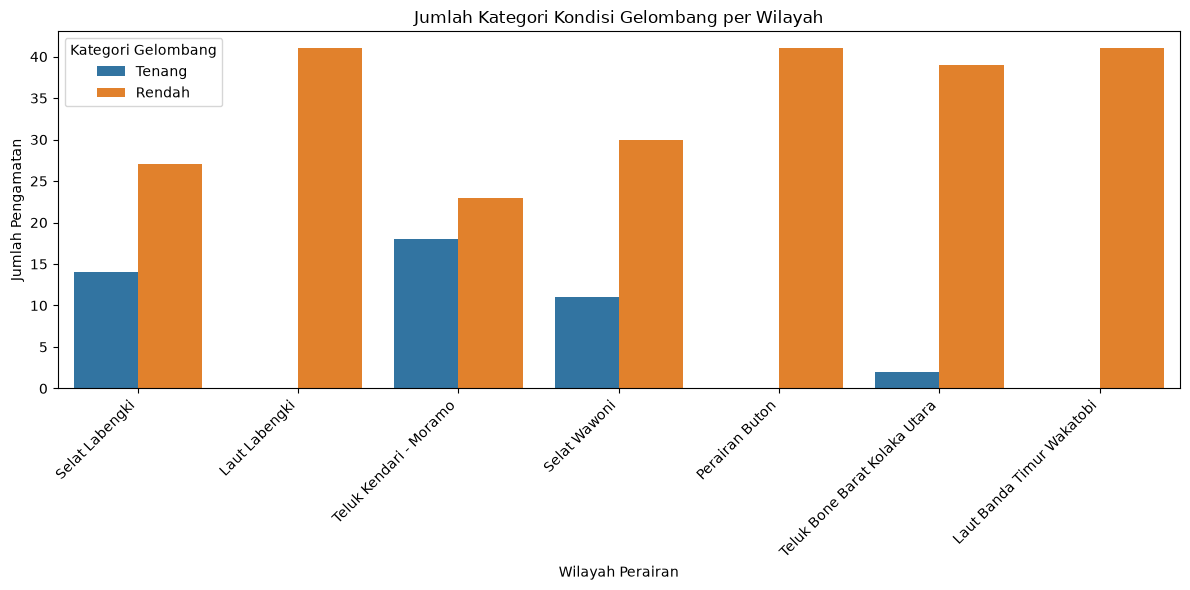

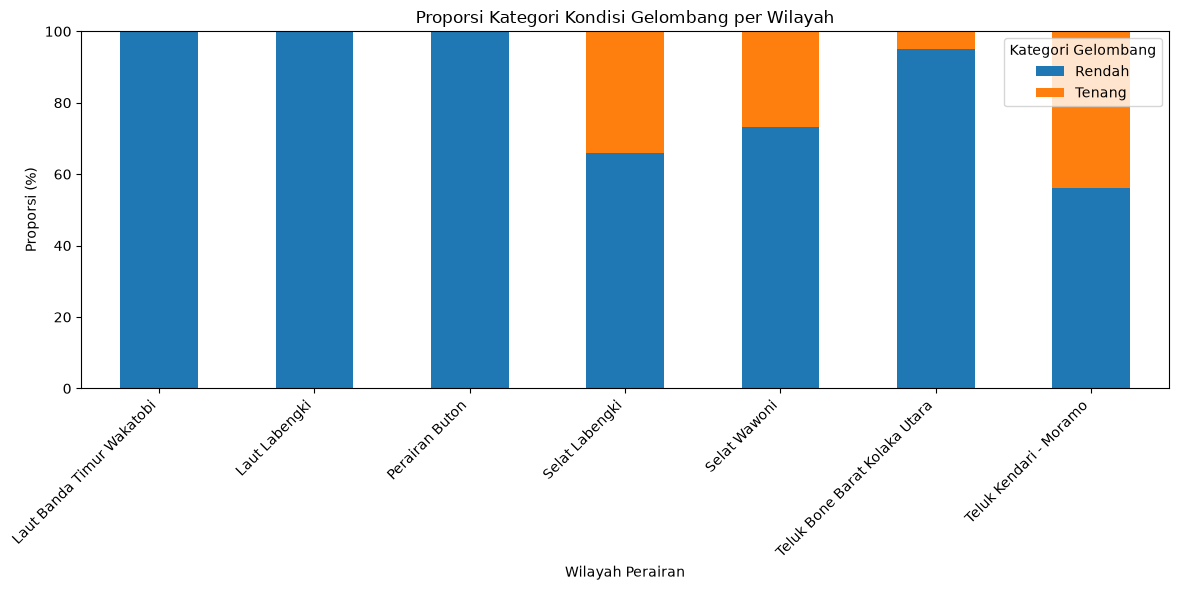

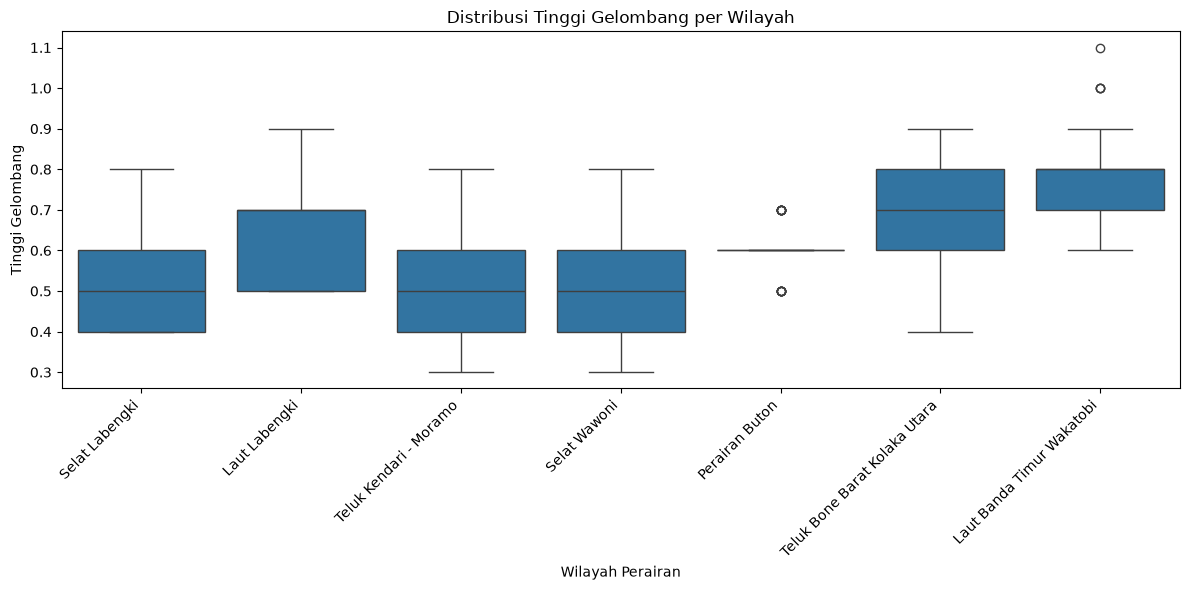

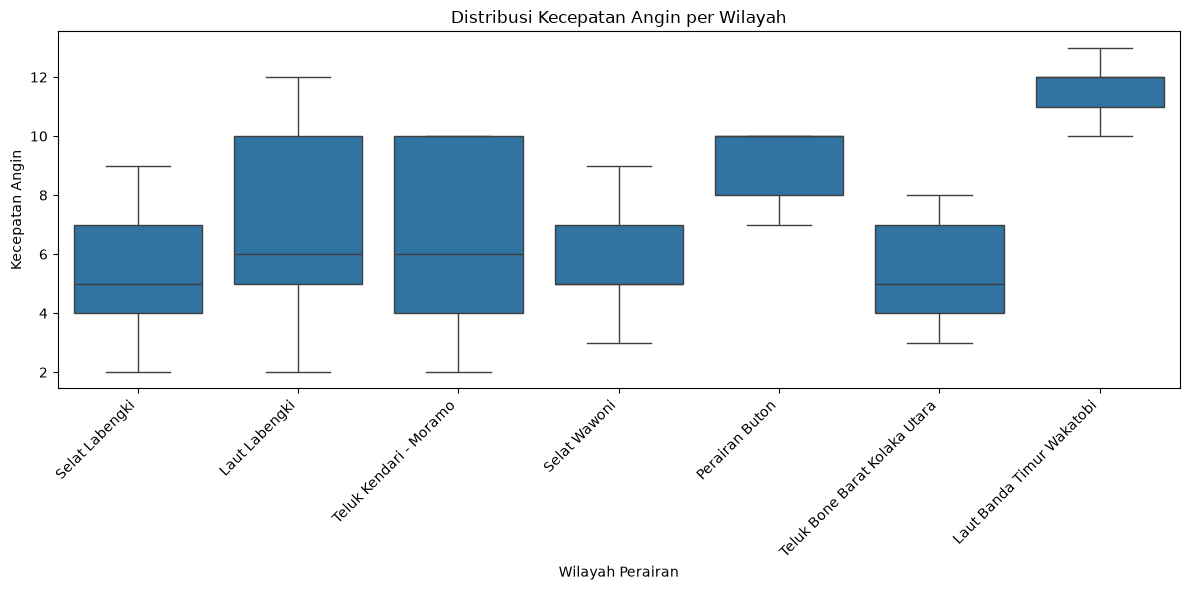


INSIGHT BQ1

Kategori gelombang dominan pada setiap wilayah:
area_name
Laut Banda Timur Wakatobi        Rendah
Laut Labengki                    Rendah
Perairan Buton                   Rendah
Selat Labengki                   Rendah
Selat Wawoni                     Rendah
Teluk Bone Barat Kolaka Utara    Rendah
Teluk Kendari - Moramo           Rendah
dtype: str

Hasil EDA BQ1 menunjukkan bahwa dataset mencakup
7 wilayah perairan dengan jumlah
pengamatan yang relatif merata. Wilayah dengan jumlah pengamatan
terbanyak adalah Selat Labengki sebanyak
41 data, sedangkan jumlah pengamatan
paling sedikit terdapat pada Selat Labengki sebanyak
41 data.

Secara keseluruhan, kategori gelombang yang paling dominan adalah
Rendah, yaitu sebanyak 242 data atau
84.32% dari seluruh pengamatan.

Berdasarkan rata-rata tinggi gelombang, wilayah dengan nilai
tertinggi adalah Laut Banda Timur Wakatobi sebesar
0.79, sedangkan nilai terendah terdapat pada
Teluk Kendari - Moramo sebesar 0.51.

Perbedaan tinggi 

In [190]:
# ============================================================
# 9. EDA - BUSINESS QUESTION 1
# ============================================================

print("\n" + "=" * 80)
print("10. EDA - BQ1")
print("=" * 80)

print("""
BQ1:
Bagaimana kondisi gelombang laut pada masing-masing wilayah
perairan berdasarkan data cuaca dan kondisi laut?
""")

# ------------------------------------------------------------
# 9.1 EKSPLORASI JUMLAH DATA PER WILAYAH
# ------------------------------------------------------------

print("\n--- JUMLAH PENGAMATAN PER WILAYAH ---")

jumlah_wilayah = (
    df["area_name"]
    .value_counts()
    .sort_values(ascending=False)
)

print(jumlah_wilayah)


# ------------------------------------------------------------
# 9.2 DISTRIBUSI KATEGORI GELOMBANG
# ------------------------------------------------------------

print("\n--- DISTRIBUSI KATEGORI GELOMBANG ---")

distribusi_kategori = (
    df["wave_category"]
    .value_counts()
)

print(distribusi_kategori)

print("\nProporsi kategori (%):")

proporsi_kategori = (
    df["wave_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(proporsi_kategori)


# ------------------------------------------------------------
# 9.3 KATEGORI GELOMBANG PER WILAYAH
# ------------------------------------------------------------

print("\n--- KATEGORI GELOMBANG PER WILAYAH ---")

tabel_bq1 = pd.crosstab(
    df["area_name"],
    df["wave_category"]
)

print(tabel_bq1)


# ------------------------------------------------------------
# 9.4 RATA-RATA KONDISI CUACA DAN LAUT PER WILAYAH
# ------------------------------------------------------------

print("\n--- RATA-RATA KONDISI PER WILAYAH ---")

ringkasan_wilayah = (
    df.groupby("area_name")[
        [
            "temperature",
            "humidity",
            "wind_speed",
            "wind_gust",
            "wave_height",
            "current_speed"
        ]
    ]
    .mean()
    .round(2)
)

print(ringkasan_wilayah)


# ------------------------------------------------------------
# 9.5 WILAYAH DENGAN RATA-RATA GELOMBANG TERTINGGI
# ------------------------------------------------------------

print("\n--- WILAYAH DENGAN RATA-RATA TINGGI GELOMBANG TERTINGGI ---")

rata_wave_wilayah = (
    df.groupby("area_name")["wave_height"]
    .mean()
    .sort_values(ascending=False)
)

print(rata_wave_wilayah.round(2))

wilayah_tertinggi = rata_wave_wilayah.idxmax()
nilai_tertinggi = rata_wave_wilayah.max()

print(
    f"\nWilayah dengan rata-rata tinggi gelombang tertinggi: "
    f"{wilayah_tertinggi} ({nilai_tertinggi:.2f})"
)


# ------------------------------------------------------------
# VISUAL 1
# JUMLAH KATEGORI GELOMBANG PER WILAYAH
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="area_name",
    hue="wave_category"
)

plt.title(
    "Jumlah Kategori Kondisi Gelombang per Wilayah"
)

plt.xlabel("Wilayah Perairan")
plt.ylabel("Jumlah Pengamatan")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq1_01_jumlah_kategori_per_wilayah.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 2
# PROPORSI KATEGORI PER WILAYAH
# ------------------------------------------------------------

proporsi_bq1 = (
    pd.crosstab(
        df["area_name"],
        df["wave_category"],
        normalize="index"
    ) * 100
)

proporsi_bq1.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title(
    "Proporsi Kategori Kondisi Gelombang per Wilayah"
)

plt.xlabel("Wilayah Perairan")
plt.ylabel("Proporsi (%)")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq1_02_proporsi_kategori_per_wilayah.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 3
# DISTRIBUSI TINGGI GELOMBANG PER WILAYAH
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="area_name",
    y="wave_height"
)

plt.title(
    "Distribusi Tinggi Gelombang per Wilayah"
)

plt.xlabel("Wilayah Perairan")
plt.ylabel("Tinggi Gelombang")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "bq1_03_boxplot_tinggi_gelombang_wilayah.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 4
# DISTRIBUSI KECEPATAN ANGIN PER WILAYAH
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="area_name",
    y="wind_speed"
)

plt.title(
    "Distribusi Kecepatan Angin per Wilayah"
)

plt.xlabel("Wilayah Perairan")
plt.ylabel("Kecepatan Angin")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "bq1_04_boxplot_angin_wilayah.png",
    dpi=300
)

plt.show()


# ============================================================
# INSIGHT EDA - BQ1
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT BQ1")
print("=" * 80)


# ------------------------------------------------------------
# INFORMASI DASAR
# ------------------------------------------------------------

jumlah_per_wilayah = jumlah_wilayah

wilayah_paling_banyak = jumlah_wilayah.idxmax()
jumlah_pengamatan_terbanyak = jumlah_wilayah.max()

wilayah_paling_sedikit = jumlah_wilayah.idxmin()
jumlah_pengamatan_tersedikit = jumlah_wilayah.min()


# ------------------------------------------------------------
# KATEGORI DOMINAN
# ------------------------------------------------------------

kategori_dominan = distribusi_kategori.idxmax()
jumlah_dominan = distribusi_kategori.max()
proporsi_dominan = proporsi_kategori[kategori_dominan]


# ------------------------------------------------------------
# WILAYAH DENGAN GELOMBANG TERTINGGI & TERENDAH
# ------------------------------------------------------------

wilayah_wave_tertinggi = rata_wave_wilayah.idxmax()
nilai_wave_tertinggi = rata_wave_wilayah.max()

wilayah_wave_terendah = rata_wave_wilayah.idxmin()
nilai_wave_terendah = rata_wave_wilayah.min()


# ------------------------------------------------------------
# RATA-RATA KONDISI ANGIN
# ------------------------------------------------------------

rata_angin_wilayah = (
    df.groupby("area_name")["wind_speed"]
    .mean()
)

wilayah_angin_tertinggi = rata_angin_wilayah.idxmax()
nilai_angin_tertinggi = rata_angin_wilayah.max()

wilayah_angin_terendah = rata_angin_wilayah.idxmin()
nilai_angin_terendah = rata_angin_wilayah.min()


# ------------------------------------------------------------
# KATEGORI DOMINAN PER WILAYAH
# ------------------------------------------------------------

kategori_per_wilayah = (
    tabel_bq1.idxmax(axis=1)
)

print("\nKategori gelombang dominan pada setiap wilayah:")
print(kategori_per_wilayah)


# ============================================================
# KESIMPULAN BQ1
# ============================================================

print(f"""
Hasil EDA BQ1 menunjukkan bahwa dataset mencakup
{jumlah_per_wilayah.shape[0]} wilayah perairan dengan jumlah
pengamatan yang relatif merata. Wilayah dengan jumlah pengamatan
terbanyak adalah {wilayah_paling_banyak} sebanyak
{jumlah_pengamatan_terbanyak} data, sedangkan jumlah pengamatan
paling sedikit terdapat pada {wilayah_paling_sedikit} sebanyak
{jumlah_pengamatan_tersedikit} data.

Secara keseluruhan, kategori gelombang yang paling dominan adalah
{kategori_dominan}, yaitu sebanyak {jumlah_dominan} data atau
{proporsi_dominan:.2f}% dari seluruh pengamatan.

Berdasarkan rata-rata tinggi gelombang, wilayah dengan nilai
tertinggi adalah {wilayah_wave_tertinggi} sebesar
{nilai_wave_tertinggi:.2f}, sedangkan nilai terendah terdapat pada
{wilayah_wave_terendah} sebesar {nilai_wave_terendah:.2f}.

Perbedaan tinggi gelombang antarwilayah juga terlihat pada kondisi
angin. Rata-rata kecepatan angin tertinggi terdapat pada
{wilayah_angin_tertinggi} sebesar {nilai_angin_tertinggi:.2f},
sedangkan yang terendah terdapat pada {wilayah_angin_terendah}
sebesar {nilai_angin_terendah:.2f}.

Hasil tersebut menunjukkan bahwa kondisi gelombang memiliki variasi
antarwilayah perairan dan dapat diamati bersama dengan perbedaan
kondisi cuaca serta kondisi laut pada masing-masing wilayah.
""")


11. EDA - BQ2

BQ2:
Bagaimana hubungan antara kecepatan angin, tinggi gelombang,
dan kecepatan arus terhadap kategori kondisi gelombang laut?


--- RATA-RATA FAKTOR BERDASARKAN KATEGORI ---
               wind_speed  wind_gust  wave_height  current_speed
wave_category                                                   
Rendah               7.86     16.248        0.656          0.957
Tenang               4.80     14.733        0.384          0.796

--- RENTANG NILAI BERDASARKAN KATEGORI ---


              wind_speed       wave_height      current_speed      
                     min   max         min  max           min   max
wave_category                                                      
Rendah               2.0  13.0         0.5  1.1          0.67  1.31
Tenang               2.0  10.0         0.3  0.4          0.67  0.96

--- KORELASI VARIABEL UTAMA ---
               wind_speed  wind_gust  wave_height  current_speed
wind_speed          1.000      0.602        0.567          0.629
wind_gust           0.602      1.000        0.212          0.400
wave_height         0.567      0.212        1.000          0.413
current_speed       0.629      0.400        0.413          1.000

--- KORELASI TERHADAP TINGGI GELOMBANG ---
wave_height      1.000
wind_speed       0.567
current_speed    0.413
wind_gust        0.212
Name: wave_height, dtype: float64


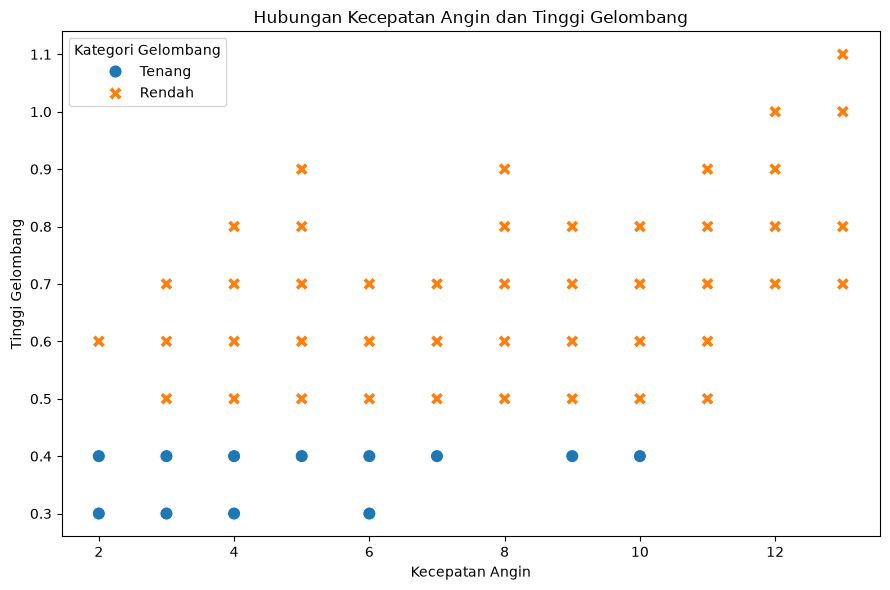

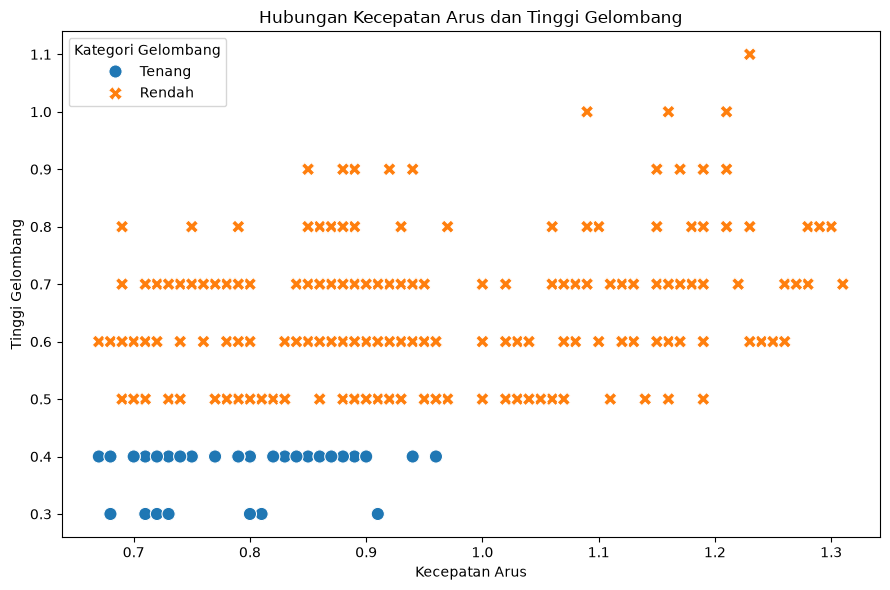

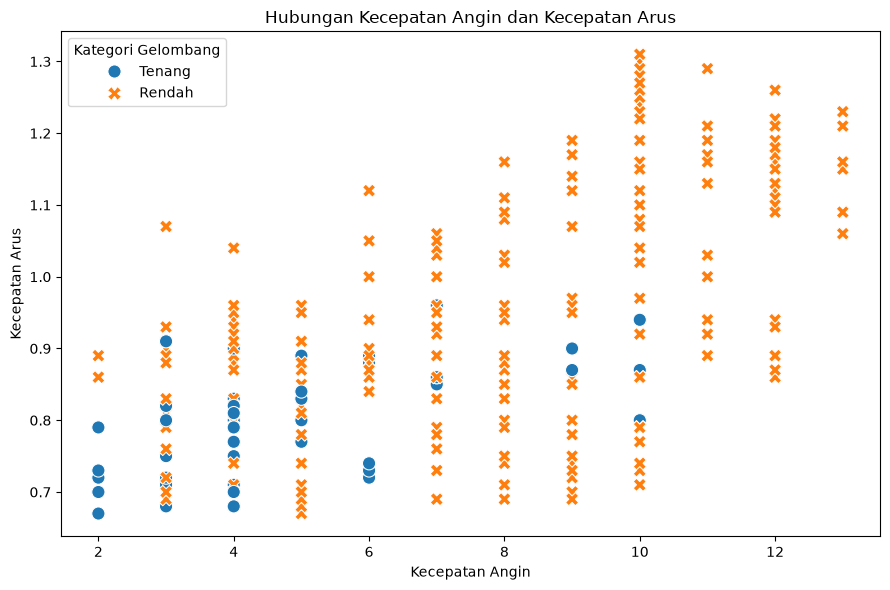

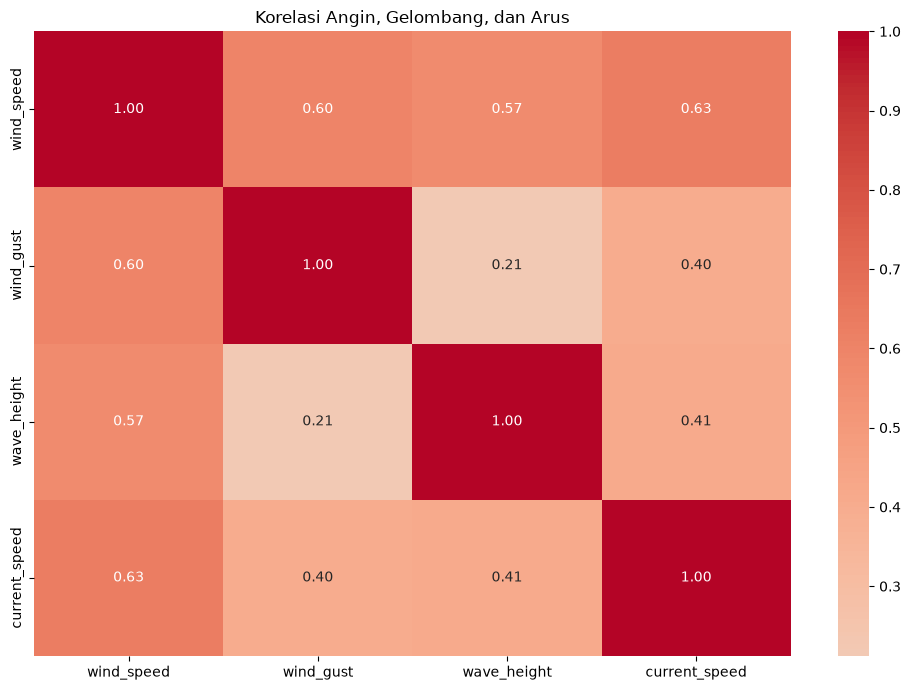

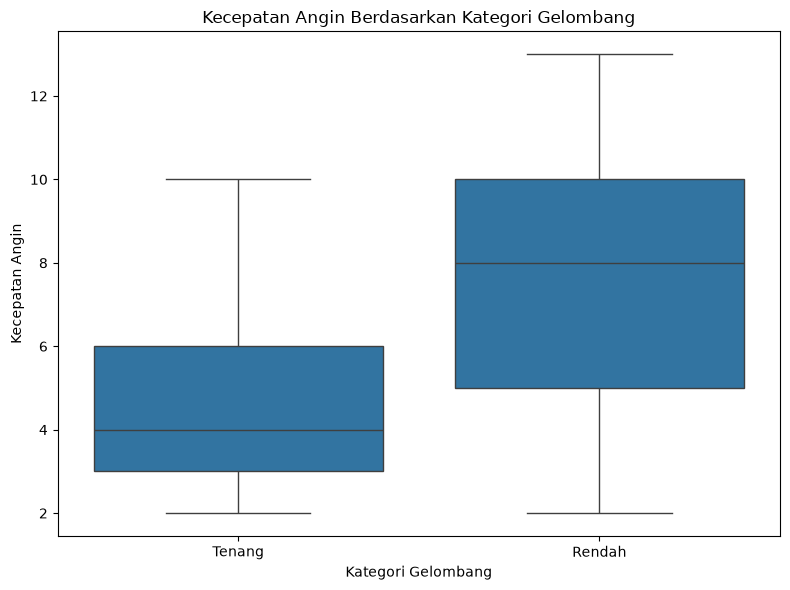

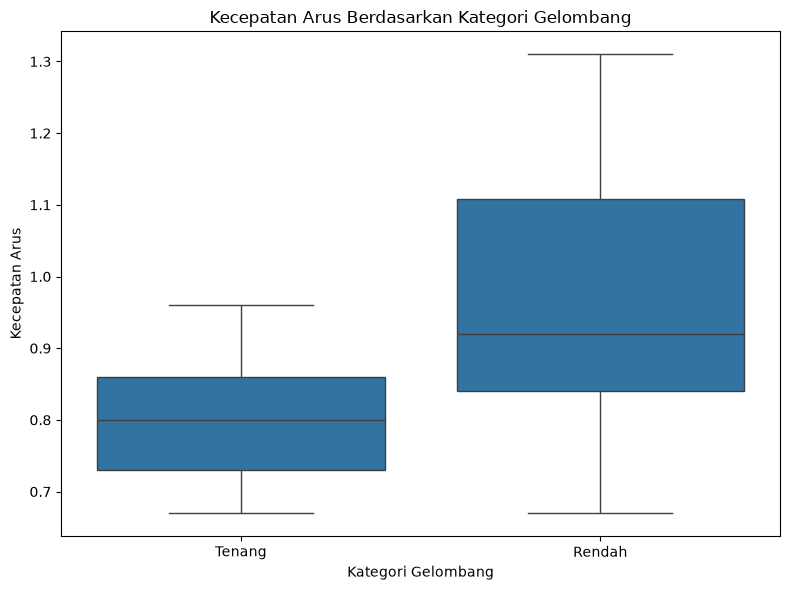


--- INSIGHT BQ2 ---
Rata-rata faktor utama berdasarkan kategori:
               wind_speed  wind_gust  wave_height  current_speed
wave_category                                                   
Rendah               7.86     16.248        0.656          0.957
Tenang               4.80     14.733        0.384          0.796

Korelasi terhadap tinggi gelombang:
wave_height      1.000
wind_speed       0.567
current_speed    0.413
wind_gust        0.212
Name: wave_height, dtype: float64

INSIGHT BQ2

Hasil EDA BQ2 menunjukkan adanya perbedaan kondisi angin, tinggi
gelombang, dan kecepatan arus antar kategori kondisi gelombang.

Kategori Rendah memiliki rata-rata tinggi
gelombang tertinggi sebesar 0.656, sedangkan
kategori Tenang memiliki rata-rata terendah
sebesar 0.384.

Berdasarkan kecepatan angin, kategori Rendah
memiliki rata-rata kecepatan angin tertinggi sebesar
7.86. Untuk kecepatan arus, kategori
Rendah memiliki rata-rata tertinggi sebesar
0.957.

Hasil korelasi menunjukkan bahwa 

In [191]:
# ============================================================
# 10. EDA - BUSINESS QUESTION 2
# ============================================================

print("\n" + "=" * 80)
print("11. EDA - BQ2")
print("=" * 80)

print("""
BQ2:
Bagaimana hubungan antara kecepatan angin, tinggi gelombang,
dan kecepatan arus terhadap kategori kondisi gelombang laut?
""")


# ------------------------------------------------------------
# 10.1 STATISTIK PER KATEGORI
# ------------------------------------------------------------

print("\n--- RATA-RATA FAKTOR BERDASARKAN KATEGORI ---")

ringkasan_kategori = (
    df.groupby("wave_category")[
        [
            "wind_speed",
            "wind_gust",
            "wave_height",
            "current_speed"
        ]
    ]
    .mean()
    .round(3)
)

print(ringkasan_kategori)


# ------------------------------------------------------------
# 10.2 MINIMUM DAN MAKSIMUM
# ------------------------------------------------------------

print("\n--- RENTANG NILAI BERDASARKAN KATEGORI ---")

rentang_kategori = (
    df.groupby("wave_category")[
        [
            "wind_speed",
            "wave_height",
            "current_speed"
        ]
    ]
    .agg(["min", "max"])
    .round(3)
)

print(rentang_kategori)


# ------------------------------------------------------------
# 10.3 KORELASI
# ------------------------------------------------------------

print("\n--- KORELASI VARIABEL UTAMA ---")

kolom_bq2 = [
    "wind_speed",
    "wind_gust",
    "wave_height",
    "current_speed"
]

korelasi_bq2 = (
    df[kolom_bq2]
    .corr()
    .round(3)
)

print(korelasi_bq2)


# ------------------------------------------------------------
# 10.4 KORELASI KHUSUS DENGAN TINGGI GELOMBANG
# ------------------------------------------------------------

print("\n--- KORELASI TERHADAP TINGGI GELOMBANG ---")

korelasi_wave = (
    df[
        [
            "wind_speed",
            "wind_gust",
            "current_speed",
            "wave_height"
        ]
    ]
    .corr()["wave_height"]
    .sort_values(ascending=False)
)

print(korelasi_wave.round(3))


# ------------------------------------------------------------
# VISUAL 5
# ANGIN VS TINGGI GELOMBANG
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="wind_speed",
    y="wave_height",
    hue="wave_category",
    style="wave_category",
    s=90
)

plt.title(
    "Hubungan Kecepatan Angin dan Tinggi Gelombang"
)

plt.xlabel("Kecepatan Angin")
plt.ylabel("Tinggi Gelombang")

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq2_05_scatter_angin_vs_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 6
# ARUS VS TINGGI GELOMBANG
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="current_speed",
    y="wave_height",
    hue="wave_category",
    style="wave_category",
    s=90
)

plt.title(
    "Hubungan Kecepatan Arus dan Tinggi Gelombang"
)

plt.xlabel("Kecepatan Arus")
plt.ylabel("Tinggi Gelombang")

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq2_06_scatter_arus_vs_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 7
# ANGIN VS ARUS
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="wind_speed",
    y="current_speed",
    hue="wave_category",
    style="wave_category",
    s=90
)

plt.title(
    "Hubungan Kecepatan Angin dan Kecepatan Arus"
)

plt.xlabel("Kecepatan Angin")
plt.ylabel("Kecepatan Arus")

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq2_07_scatter_angin_vs_arus.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 8
# HEATMAP KORELASI
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.heatmap(
    korelasi_bq2,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Korelasi Angin, Gelombang, dan Arus"
)

plt.tight_layout()

plt.savefig(
    "bq2_08_correlation_heatmap.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 9
# ANGIN BERDASARKAN KATEGORI
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="wave_category",
    y="wind_speed"
)

plt.title(
    "Kecepatan Angin Berdasarkan Kategori Gelombang"
)

plt.xlabel("Kategori Gelombang")
plt.ylabel("Kecepatan Angin")

plt.tight_layout()

plt.savefig(
    "bq2_09_boxplot_angin_kategori.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 10
# ARUS BERDASARKAN KATEGORI
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="wave_category",
    y="current_speed"
)

plt.title(
    "Kecepatan Arus Berdasarkan Kategori Gelombang"
)

plt.xlabel("Kategori Gelombang")
plt.ylabel("Kecepatan Arus")

plt.tight_layout()

plt.savefig(
    "bq2_10_boxplot_arus_kategori.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# INSIGHT BQ2
# ------------------------------------------------------------

print("\n--- INSIGHT BQ2 ---")

print(
    "Rata-rata faktor utama berdasarkan kategori:"
)

print(
    ringkasan_kategori
)

print(
    "\nKorelasi terhadap tinggi gelombang:"
)

print(
    korelasi_wave.round(3)
)

# ============================================================
# INSIGHT EDA - BQ2
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT BQ2")
print("=" * 80)


# ------------------------------------------------------------
# RATA-RATA BERDASARKAN KATEGORI
# ------------------------------------------------------------

rata_wave_kategori = (
    df.groupby("wave_category")["wave_height"]
    .mean()
)

rata_angin_kategori = (
    df.groupby("wave_category")["wind_speed"]
    .mean()
)

rata_arus_kategori = (
    df.groupby("wave_category")["current_speed"]
    .mean()
)


# ------------------------------------------------------------
# KORELASI TERHADAP TINGGI GELOMBANG
# ------------------------------------------------------------

korelasi_wave = (
    df[
        [
            "wind_speed",
            "wind_gust",
            "current_speed",
            "wave_height"
        ]
    ]
    .corr()["wave_height"]
    .sort_values(ascending=False)
)

korelasi_tanpa_target = (
    korelasi_wave
    .drop("wave_height")
)

variabel_korelasi_tertinggi = (
    korelasi_tanpa_target
    .idxmax()
)

nilai_korelasi_tertinggi = (
    korelasi_tanpa_target
    .max()
)


# ------------------------------------------------------------
# KATEGORI DENGAN RATA-RATA GELOMBANG TERTINGGI
# ------------------------------------------------------------

kategori_wave_tertinggi = (
    rata_wave_kategori.idxmax()
)

nilai_wave_tertinggi = (
    rata_wave_kategori.max()
)

kategori_wave_terendah = (
    rata_wave_kategori.idxmin()
)

nilai_wave_terendah = (
    rata_wave_kategori.min()
)


# ------------------------------------------------------------
# KATEGORI DENGAN RATA-RATA ANGIN TERTINGGI
# ------------------------------------------------------------

kategori_angin_tertinggi = (
    rata_angin_kategori.idxmax()
)

nilai_angin_tertinggi = (
    rata_angin_kategori.max()
)


# ------------------------------------------------------------
# KATEGORI DENGAN RATA-RATA ARUS TERTINGGI
# ------------------------------------------------------------

kategori_arus_tertinggi = (
    rata_arus_kategori.idxmax()
)

nilai_arus_tertinggi = (
    rata_arus_kategori.max()
)


# ============================================================
# KESIMPULAN BQ2
# ============================================================

print(f"""
Hasil EDA BQ2 menunjukkan adanya perbedaan kondisi angin, tinggi
gelombang, dan kecepatan arus antar kategori kondisi gelombang.

Kategori {kategori_wave_tertinggi} memiliki rata-rata tinggi
gelombang tertinggi sebesar {nilai_wave_tertinggi:.3f}, sedangkan
kategori {kategori_wave_terendah} memiliki rata-rata terendah
sebesar {nilai_wave_terendah:.3f}.

Berdasarkan kecepatan angin, kategori {kategori_angin_tertinggi}
memiliki rata-rata kecepatan angin tertinggi sebesar
{nilai_angin_tertinggi:.2f}. Untuk kecepatan arus, kategori
{kategori_arus_tertinggi} memiliki rata-rata tertinggi sebesar
{nilai_arus_tertinggi:.3f}.

Hasil korelasi menunjukkan bahwa {variabel_korelasi_tertinggi}
memiliki hubungan positif paling kuat dengan tinggi gelombang
dengan nilai korelasi sebesar {nilai_korelasi_tertinggi:.3f}.
Variabel lainnya menunjukkan hubungan yang lebih rendah terhadap
tinggi gelombang.

Dengan demikian, pada dataset ini terdapat hubungan antara
kecepatan angin, kecepatan arus, dan tinggi gelombang dengan
kategori kondisi gelombang. Hasil korelasi menunjukkan hubungan
antarvariabel, tetapi tidak digunakan untuk menyimpulkan hubungan
sebab-akibat.
""")

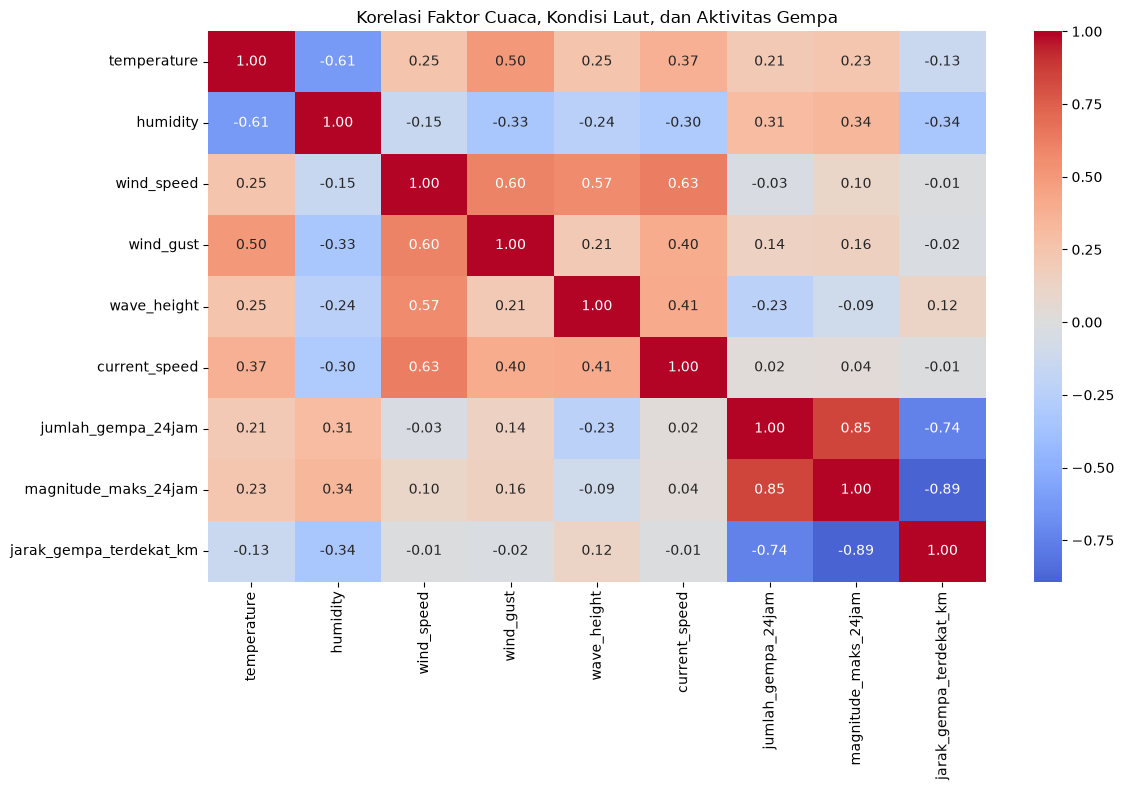

In [192]:
# ------------------------------------------------------------
# VISUAL 8
# CORRELATION HEATMAP
# ------------------------------------------------------------

kolom_korelasi = [
    "temperature",
    "humidity",
    "wind_speed",
    "wind_gust",
    "wave_height",
    "current_speed",
    "jumlah_gempa_24jam",
    "magnitude_maks_24jam",
    "jarak_gempa_terdekat_km"
]

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[kolom_korelasi].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Korelasi Faktor Cuaca, Kondisi Laut, dan Aktivitas Gempa"
)

plt.tight_layout()

plt.savefig(
    "bq2_08_correlation_heatmap.png",
    dpi=300
)

plt.show()



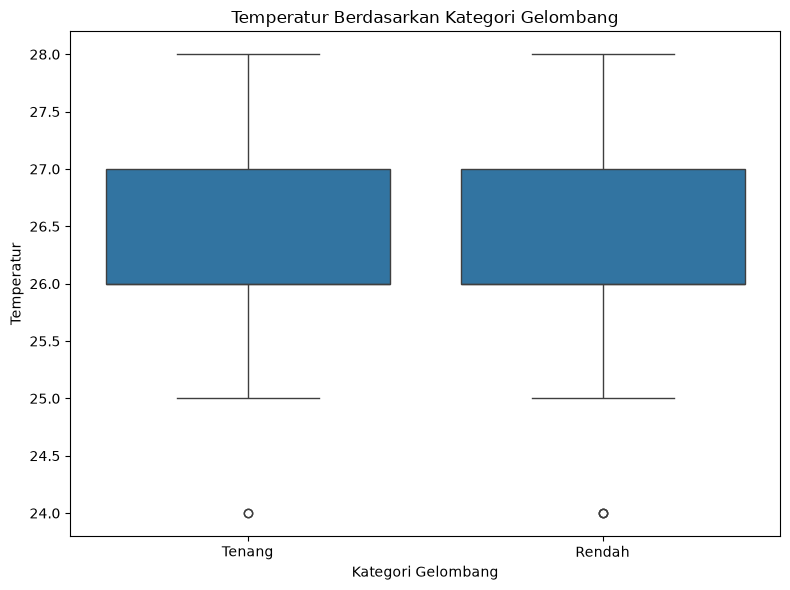

In [193]:
# ------------------------------------------------------------
# VISUAL 11
# BOXPLOT TEMPERATUR BERDASARKAN KATEGORI
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="wave_category",
    y="temperature"
)

plt.title(
    "Temperatur Berdasarkan Kategori Gelombang"
)

plt.xlabel("Kategori Gelombang")
plt.ylabel("Temperatur")

plt.tight_layout()

plt.savefig(
    "bq2_11_boxplot_temperature_kategori.png",
    dpi=300
)

plt.show()


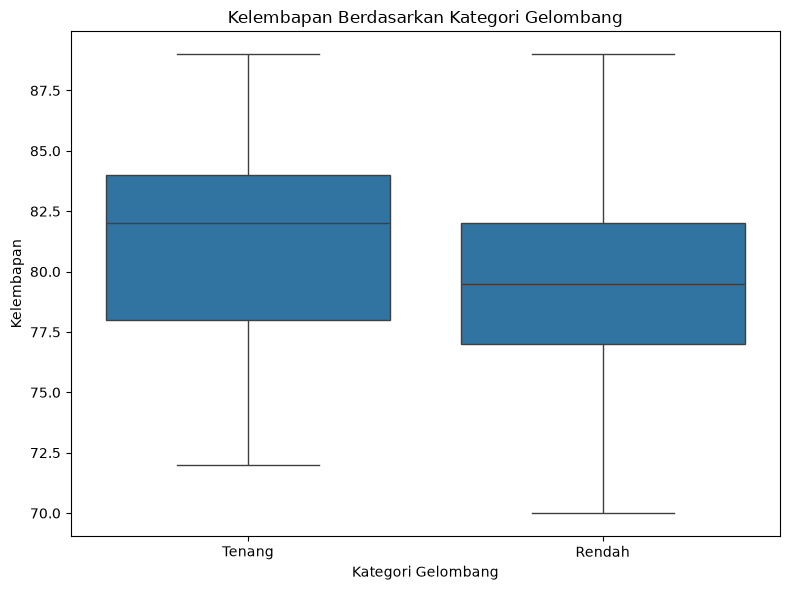

In [194]:
# ------------------------------------------------------------
# VISUAL 12
# BOXPLOT HUMIDITY BERDASARKAN KATEGORI
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="wave_category",
    y="humidity"
)

plt.title(
    "Kelembapan Berdasarkan Kategori Gelombang"
)

plt.xlabel("Kategori Gelombang")
plt.ylabel("Kelembapan")

plt.tight_layout()

plt.savefig(
    "bq2_12_boxplot_humidity_kategori.png",
    dpi=300
)

plt.show()



12. EDA - BQ3

BQ3:
Bagaimana perbedaan kondisi gelombang laut berdasarkan lokasi
wilayah perairan dan waktu pengamatan?


--- RATA-RATA TINGGI GELOMBANG PER WILAYAH ---
                               rata_wave  min_wave  max_wave  rata_angin  \
area_name                                                                  
Laut Banda Timur Wakatobi          0.790       0.6       1.1      11.610   
Teluk Bone Barat Kolaka Utara      0.676       0.4       0.9       5.439   
Laut Labengki                      0.646       0.5       0.9       7.293   
Perairan Buton                     0.602       0.5       0.7       9.146   
Selat Labengki                     0.537       0.4       0.8       5.829   
Selat Wawoni                       0.532       0.3       0.8       5.805   
Teluk Kendari - Moramo             0.510       0.3       0.8       6.537   

                               rata_arus  
area_name                                 
Laut Banda Timur Wakatobi          1.184  
Teluk Bone Bara

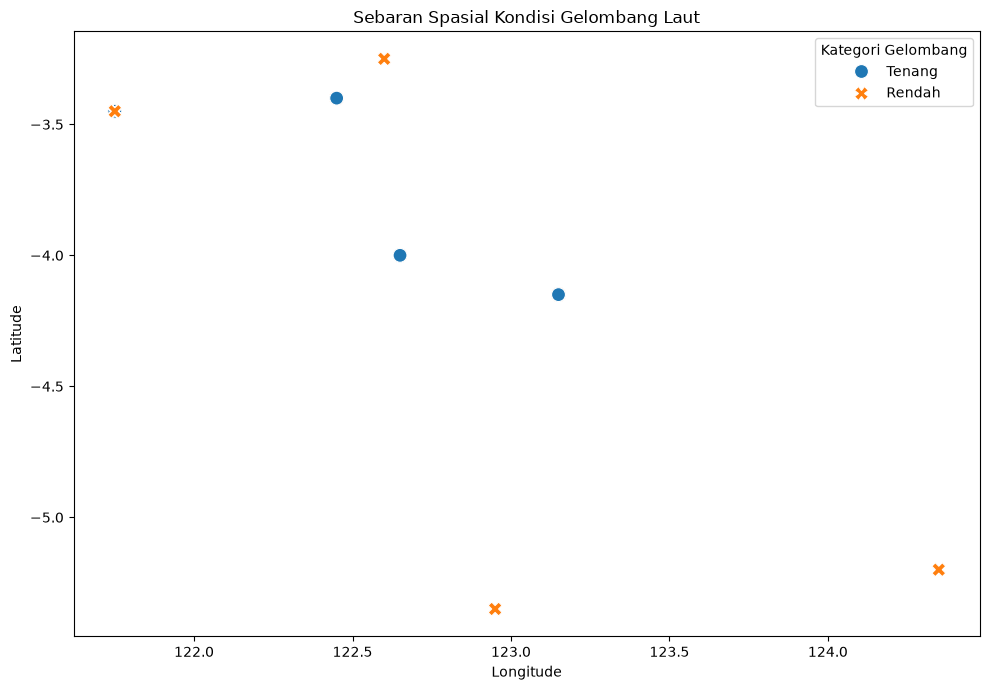

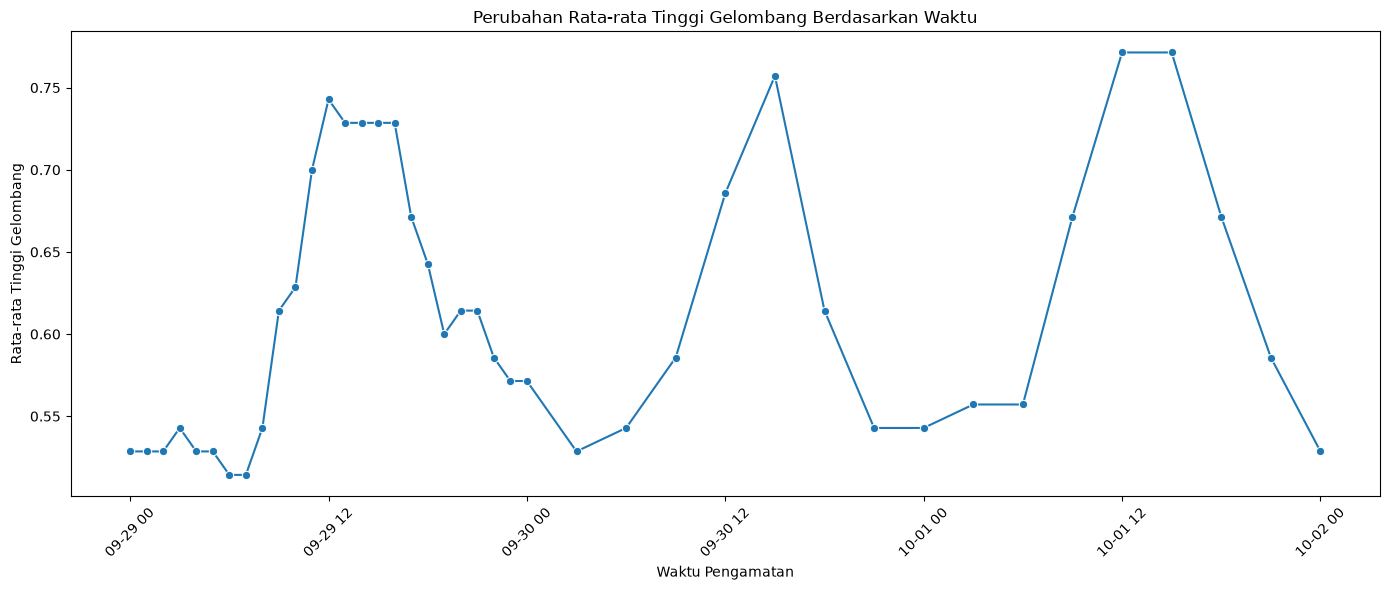

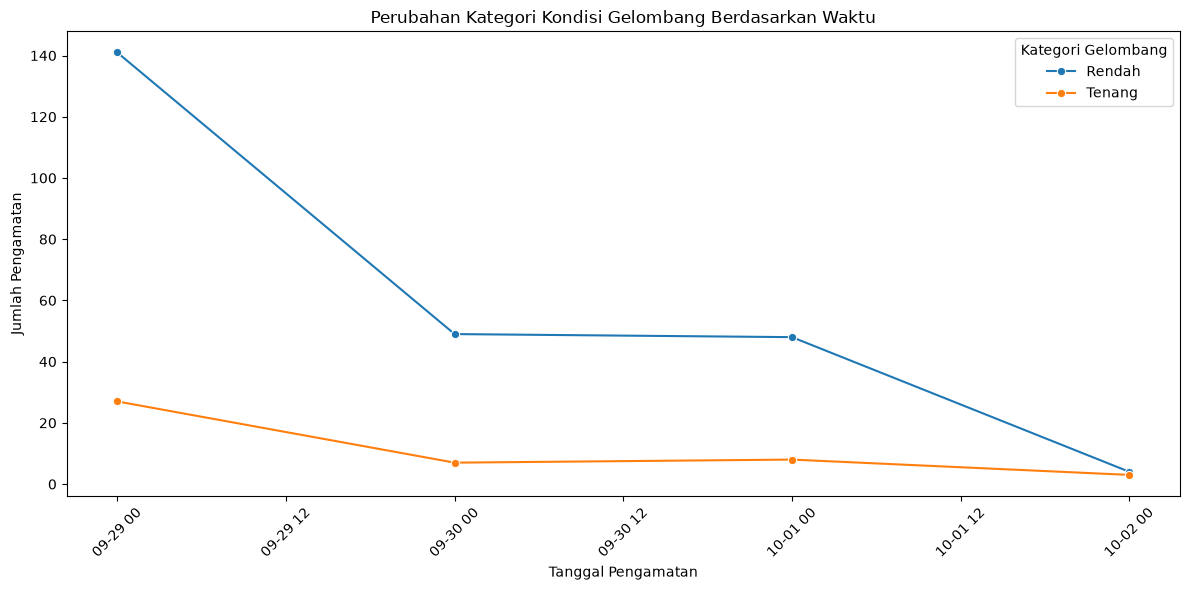

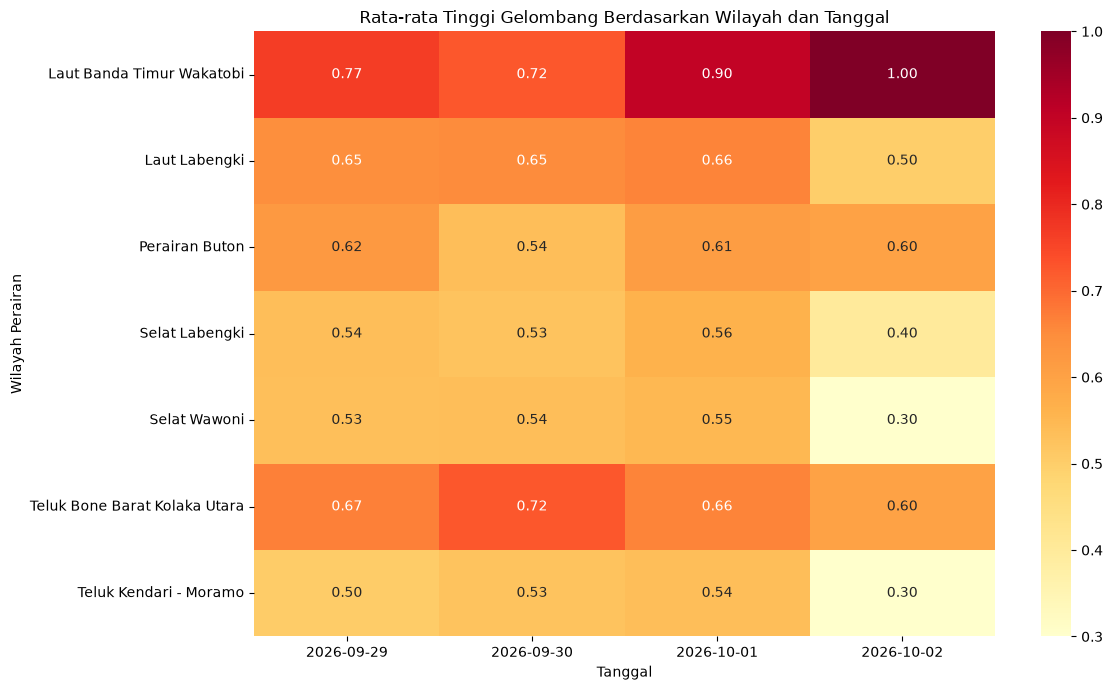


INSIGHT BQ3

Hasil EDA BQ3 menunjukkan adanya perbedaan kondisi gelombang
berdasarkan lokasi wilayah perairan dan waktu pengamatan.

Berdasarkan lokasi, wilayah Laut Banda Timur Wakatobi memiliki
rata-rata tinggi gelombang tertinggi sebesar
0.790, sedangkan Teluk Kendari - Moramo
memiliki rata-rata terendah sebesar 0.510.

Berdasarkan waktu pengamatan, rata-rata tinggi gelombang tertinggi
terjadi pada pukul 15:00 dengan nilai
0.752, sedangkan nilai terendah terjadi pada
pukul 07:00 dengan nilai
0.514.

Berdasarkan hari pengamatan, rata-rata tinggi gelombang tertinggi
terdapat pada hari Thursday sebesar
0.641, sedangkan rata-rata terendah terdapat
pada hari Friday sebesar 0.529.

Untuk distribusi kategori berdasarkan wilayah, proporsi kategori
Tenang tertinggi terdapat pada Teluk Kendari - Moramo dengan
proporsi sebesar 43.90% apabila kategori
Tenang tersedia pada dataset.

Hasil tersebut menunjukkan bahwa kondisi gelombang pada dataset
memiliki variasi berdasarkan lokasi wilayah perai

In [195]:
# ============================================================
# 11. EDA - BUSINESS QUESTION 3
# ============================================================

print("\n" + "=" * 80)
print("12. EDA - BQ3")
print("=" * 80)

print("""
BQ3:
Bagaimana perbedaan kondisi gelombang laut berdasarkan lokasi
wilayah perairan dan waktu pengamatan?
""")


# ------------------------------------------------------------
# 12.1 EKSPLORASI SPASIAL
# ------------------------------------------------------------

print("\n--- RATA-RATA TINGGI GELOMBANG PER WILAYAH ---")

spasial = (
    df.groupby("area_name")
    .agg(
        rata_wave=("wave_height", "mean"),
        min_wave=("wave_height", "min"),
        max_wave=("wave_height", "max"),
        rata_angin=("wind_speed", "mean"),
        rata_arus=("current_speed", "mean")
    )
    .sort_values(
        "rata_wave",
        ascending=False
    )
    .round(3)
)

print(spasial)


# ------------------------------------------------------------
# 11.2 KONDISI BERDASARKAN WAKTU
# Tidak membuat kolom baru
# ------------------------------------------------------------

print("\n--- RATA-RATA TINGGI GELOMBANG PER JAM ---")

per_jam = (
    df.groupby(
        df["forecast_time"].dt.hour
    )["wave_height"]
    .mean()
    .round(3)
)

print(per_jam)


# ------------------------------------------------------------
# 11.3 KONDISI BERDASARKAN HARI
# Tidak membuat kolom baru
# ------------------------------------------------------------

print("\n--- RATA-RATA TINGGI GELOMBANG PER HARI ---")

per_hari = (
    df.groupby(
        df["forecast_time"].dt.day_name()
    )["wave_height"]
    .mean()
    .round(3)
)

print(per_hari)


# ------------------------------------------------------------
# 11.4 DISTRIBUSI KATEGORI PER WILAYAH
# ------------------------------------------------------------

print("\n--- DISTRIBUSI KATEGORI PER WILAYAH ---")

distribusi_lokasi = (
    pd.crosstab(
        df["area_name"],
        df["wave_category"],
        normalize="index"
    ) * 100
)

print(
    distribusi_lokasi.round(2)
)


# ------------------------------------------------------------
# VISUAL 13
# SPATIAL DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="wave_category",
    style="wave_category",
    s=100
)

plt.title(
    "Sebaran Spasial Kondisi Gelombang Laut"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq3_13_spatial_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 14
# PERUBAHAN TINGGI GELOMBANG BERDASARKAN WAKTU
# ------------------------------------------------------------

temporal_wave = (
    df.groupby("forecast_time")["wave_height"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=temporal_wave,
    x="forecast_time",
    y="wave_height",
    marker="o"
)

plt.title(
    "Perubahan Rata-rata Tinggi Gelombang Berdasarkan Waktu"
)

plt.xlabel("Waktu Pengamatan")
plt.ylabel("Rata-rata Tinggi Gelombang")

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.savefig(
    "bq3_14_temporal_tinggi_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 15
# PERUBAHAN KATEGORI BERDASARKAN WAKTU
# ------------------------------------------------------------

temporal_category = (
    df.groupby(
        [
            pd.Grouper(
                key="forecast_time",
                freq="D"
            ),
            "wave_category"
        ]
    )
    .size()
    .reset_index(
        name="jumlah"
    )
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=temporal_category,
    x="forecast_time",
    y="jumlah",
    hue="wave_category",
    marker="o"
)

plt.title(
    "Perubahan Kategori Kondisi Gelombang Berdasarkan Waktu"
)

plt.xlabel("Tanggal Pengamatan")
plt.ylabel("Jumlah Pengamatan")

plt.xticks(
    rotation=45
)

plt.legend(
    title="Kategori Gelombang"
)

plt.tight_layout()

plt.savefig(
    "bq3_15_temporal_kategori_gelombang.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# VISUAL 16
# HEATMAP WILAYAH × TANGGAL
# Menggunakan forecast_time langsung
# ------------------------------------------------------------

heatmap_waktu = df.pivot_table(
    index="area_name",
    columns=df["forecast_time"].dt.date,
    values="wave_height",
    aggfunc="mean"
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_waktu,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title(
    "Rata-rata Tinggi Gelombang Berdasarkan Wilayah dan Tanggal"
)

plt.xlabel("Tanggal")
plt.ylabel("Wilayah Perairan")

plt.tight_layout()

plt.savefig(
    "bq3_16_heatmap_wilayah_waktu.png",
    dpi=300
)

plt.show()


# ============================================================
# INSIGHT BQ3
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT BQ3")
print("=" * 80)


# ------------------------------------------------------------
# WILAYAH DENGAN GELOMBANG TERTINGGI DAN TERENDAH
# ------------------------------------------------------------

wilayah_wave_tertinggi = (
    spasial["rata_wave"].idxmax()
)

nilai_wave_tertinggi = (
    spasial["rata_wave"].max()
)

wilayah_wave_terendah = (
    spasial["rata_wave"].idxmin()
)

nilai_wave_terendah = (
    spasial["rata_wave"].min()
)


# ------------------------------------------------------------
# JAM DENGAN GELOMBANG TERTINGGI DAN TERENDAH
# ------------------------------------------------------------

jam_wave_tertinggi = (
    per_jam.idxmax()
)

nilai_jam_tertinggi = (
    per_jam.max()
)

jam_wave_terendah = (
    per_jam.idxmin()
)

nilai_jam_terendah = (
    per_jam.min()
)


# ------------------------------------------------------------
# HARI DENGAN GELOMBANG TERTINGGI DAN TERENDAH
# ------------------------------------------------------------

hari_wave_tertinggi = (
    per_hari.idxmax()
)

nilai_hari_tertinggi = (
    per_hari.max()
)

hari_wave_terendah = (
    per_hari.idxmin()
)

nilai_hari_terendah = (
    per_hari.min()
)


# ------------------------------------------------------------
# WILAYAH DENGAN PROPORSI TENANG TERTINGGI
# ------------------------------------------------------------

if "Tenang" in distribusi_lokasi.columns:

    wilayah_tenang_tertinggi = (
        distribusi_lokasi["Tenang"].idxmax()
    )

    proporsi_tenang_tertinggi = (
        distribusi_lokasi["Tenang"].max()
    )

else:

    wilayah_tenang_tertinggi = "Tidak tersedia"
    proporsi_tenang_tertinggi = 0


# ============================================================
# KESIMPULAN BQ3
# ============================================================

print(f"""
Hasil EDA BQ3 menunjukkan adanya perbedaan kondisi gelombang
berdasarkan lokasi wilayah perairan dan waktu pengamatan.

Berdasarkan lokasi, wilayah {wilayah_wave_tertinggi} memiliki
rata-rata tinggi gelombang tertinggi sebesar
{nilai_wave_tertinggi:.3f}, sedangkan {wilayah_wave_terendah}
memiliki rata-rata terendah sebesar {nilai_wave_terendah:.3f}.

Berdasarkan waktu pengamatan, rata-rata tinggi gelombang tertinggi
terjadi pada pukul {jam_wave_tertinggi:02d}:00 dengan nilai
{nilai_jam_tertinggi:.3f}, sedangkan nilai terendah terjadi pada
pukul {jam_wave_terendah:02d}:00 dengan nilai
{nilai_jam_wave_terendah if False else nilai_jam_terendah:.3f}.

Berdasarkan hari pengamatan, rata-rata tinggi gelombang tertinggi
terdapat pada hari {hari_wave_tertinggi} sebesar
{nilai_hari_tertinggi:.3f}, sedangkan rata-rata terendah terdapat
pada hari {hari_wave_terendah} sebesar {nilai_hari_terendah:.3f}.

Untuk distribusi kategori berdasarkan wilayah, proporsi kategori
Tenang tertinggi terdapat pada {wilayah_tenang_tertinggi} dengan
proporsi sebesar {proporsi_tenang_tertinggi:.2f}% apabila kategori
Tenang tersedia pada dataset.

Hasil tersebut menunjukkan bahwa kondisi gelombang pada dataset
memiliki variasi berdasarkan lokasi wilayah perairan maupun waktu
pengamatan.
""")

In [196]:
# ============================================================
# 12. MACHINE LEARNING - DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("14. MACHINE LEARNING - DECISION TREE")
print("=" * 80)

print("""
BQ4:
Dapatkah kondisi gelombang laut diklasifikasikan menjadi kategori
Tenang dan Rendah berdasarkan faktor cuaca, kondisi laut, lokasi,
waktu, dan aktivitas gempa?
""")


# ------------------------------------------------------------
# FITUR MODEL
# ------------------------------------------------------------
#
# wave_height TIDAK dimasukkan sebagai fitur model
# karena sangat berkaitan dengan pembentukan kategori gelombang
# dan dapat menyebabkan target leakage.
#
# forecast_time tetap ada di dataset untuk analisis waktu pada EDA,
# tetapi tidak dibuat menjadi fitur tambahan untuk model.
# ------------------------------------------------------------

fitur = [

    # lokasi
    "latitude",
    "longitude",

    # cuaca
    "temperature",
    "humidity",
    "wind_speed",
    "wind_gust",

    # kondisi laut
    "current_speed",

    # aktivitas gempa
    "jumlah_gempa_24jam",
    "magnitude_maks_24jam",
    "jarak_gempa_terdekat_km"
]


target = "wave_category"

X = df[fitur]

y = df[target]


print("\nJumlah fitur:", len(fitur))

print("\nFitur yang digunakan:")

for nomor, nama_fitur in enumerate(
    fitur,
    start=1
):
    print(
        f"{nomor}. {nama_fitur}"
    )


print("\nDistribusi target:")
print(y.value_counts())

# ============================================================
# INSIGHT BQ4 - DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT BQ4")
print("=" * 80)

jumlah_data = len(y)

distribusi_target = y.value_counts()

jumlah_rendah = distribusi_target.get("Rendah", 0)
jumlah_tenang = distribusi_target.get("Tenang", 0)

proporsi_rendah = jumlah_rendah / jumlah_data * 100
proporsi_tenang = jumlah_tenang / jumlah_data * 100

kategori_dominan = distribusi_target.idxmax()
jumlah_dominan = distribusi_target.max()
proporsi_dominan = jumlah_dominan / jumlah_data * 100

kategori_minoritas = distribusi_target.idxmin()
jumlah_minoritas = distribusi_target.min()
proporsi_minoritas = jumlah_minoritas / jumlah_data * 100

print(f"""
Pada tahap klasifikasi, digunakan {len(fitur)} fitur asli yang
mencakup informasi lokasi, kondisi cuaca, kondisi laut, dan aktivitas
gempa untuk memprediksi kategori kondisi gelombang laut. Variabel
wave_height tidak digunakan sebagai fitur model untuk menghindari
target leakage, sedangkan forecast_time tidak diubah menjadi fitur
tambahan karena feature engineering tidak digunakan dalam penelitian.

Dataset memiliki {jumlah_data:,} data dengan dua kategori target.
Kategori {kategori_dominan} merupakan kategori yang paling dominan,
yaitu sebanyak {jumlah_dominan:,} data ({proporsi_dominan:.2f}%),
sedangkan kategori {kategori_minoritas} sebanyak
{jumlah_minoritas:,} data ({proporsi_minoritas:.2f}%).

Hasil tersebut menunjukkan bahwa distribusi target tidak seimbang,
sehingga kondisi ini perlu diperhatikan pada tahap pelatihan dan
evaluasi model klasifikasi.
""")


14. MACHINE LEARNING - DECISION TREE

BQ4:
Dapatkah kondisi gelombang laut diklasifikasikan menjadi kategori
Tenang dan Rendah berdasarkan faktor cuaca, kondisi laut, lokasi,
waktu, dan aktivitas gempa?


Jumlah fitur: 10

Fitur yang digunakan:
1. latitude
2. longitude
3. temperature
4. humidity
5. wind_speed
6. wind_gust
7. current_speed
8. jumlah_gempa_24jam
9. magnitude_maks_24jam
10. jarak_gempa_terdekat_km

Distribusi target:
wave_category
Rendah    242
Tenang     45
Name: count, dtype: int64

INSIGHT BQ4

Pada tahap klasifikasi, digunakan 10 fitur asli yang
mencakup informasi lokasi, kondisi cuaca, kondisi laut, dan aktivitas
gempa untuk memprediksi kategori kondisi gelombang laut. Variabel
wave_height tidak digunakan sebagai fitur model untuk menghindari
target leakage, sedangkan forecast_time tidak diubah menjadi fitur
tambahan karena feature engineering tidak digunakan dalam penelitian.

Dataset memiliki 287 data dengan dua kategori target.
Kategori Rendah merupakan kategori 

In [197]:
# ============================================================
# 13. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)


print("\n" + "=" * 80)
print("TRAIN TEST SPLIT")
print("=" * 80)

print("Data training :", X_train.shape)
print("Data testing  :", X_test.shape)

# ============================================================
# INSIGHT TRAIN TEST SPLIT
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT TRAIN TEST SPLIT")
print("=" * 80)

jumlah_training = X_train.shape[0]
jumlah_testing = X_test.shape[0]
jumlah_total = jumlah_training + jumlah_testing

proporsi_training = (jumlah_training / jumlah_total) * 100
proporsi_testing = (jumlah_testing / jumlah_total) * 100

print(f"""
Dataset dibagi menjadi data training sebanyak {jumlah_training} data
({proporsi_training:.2f}%) dan data testing sebanyak {jumlah_testing}
data ({proporsi_testing:.2f}%). Data training digunakan untuk melatih
model Decision Tree, sedangkan data testing digunakan untuk menguji
kemampuan model dalam melakukan prediksi terhadap data yang belum
digunakan selama proses pelatihan.
""")



TRAIN TEST SPLIT
Data training : (229, 10)
Data testing  : (58, 10)

INSIGHT TRAIN TEST SPLIT

Dataset dibagi menjadi data training sebanyak 229 data
(79.79%) dan data testing sebanyak 58
data (20.21%). Data training digunakan untuk melatih
model Decision Tree, sedangkan data testing digunakan untuk menguji
kemampuan model dalam melakukan prediksi terhadap data yang belum
digunakan selama proses pelatihan.



In [198]:
# ============================================================
# 14. PIPELINE DECISION TREE
# ============================================================

model = Pipeline(
    steps=[

        (
            "classifier",
            DecisionTreeClassifier(

                criterion="gini",

                max_depth=4,

                min_samples_split=10,

                min_samples_leaf=5,

                random_state=42,

                class_weight="balanced"
            )
        )
    ]
)


# ============================================================
# INSIGHT PIPELINE DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT PIPELINE DECISION TREE")
print("=" * 80)

classifier = model.named_steps["classifier"]

criterion = classifier.criterion
max_depth = classifier.max_depth
min_samples_split = classifier.min_samples_split
min_samples_leaf = classifier.min_samples_leaf
class_weight = classifier.class_weight

print(f"""
Pipeline digunakan untuk mengatur proses pembentukan model
Decision Tree dalam satu alur. Model digunakan untuk melakukan
klasifikasi kategori kondisi gelombang laut menjadi Tenang dan
Rendah berdasarkan {len(fitur)} fitur yang telah ditentukan.

Model menggunakan criterion {criterion} sebagai metode untuk
menentukan pemisahan data pada setiap node. Kedalaman maksimum
pohon dibatasi hingga {max_depth}, sedangkan setiap node harus
memiliki minimal {min_samples_split} data untuk dapat dilakukan
pemisahan dan setiap leaf memiliki minimal {min_samples_leaf} data.

Pengaturan tersebut digunakan untuk membatasi kompleksitas model
agar struktur Decision Tree tidak terlalu kompleks. Selain itu,
class_weight={class_weight} digunakan untuk memberikan bobot yang
lebih seimbang terhadap setiap kategori target karena distribusi
data Tenang dan Rendah tidak sama.

Dengan demikian, pipeline membantu menjaga proses pembentukan model
tetap terstruktur dan parameter Decision Tree dapat diterapkan secara
konsisten pada tahap pelatihan dan pengujian.
""")


INSIGHT PIPELINE DECISION TREE

Pipeline digunakan untuk mengatur proses pembentukan model
Decision Tree dalam satu alur. Model digunakan untuk melakukan
klasifikasi kategori kondisi gelombang laut menjadi Tenang dan
Rendah berdasarkan 10 fitur yang telah ditentukan.

Model menggunakan criterion gini sebagai metode untuk
menentukan pemisahan data pada setiap node. Kedalaman maksimum
pohon dibatasi hingga 4, sedangkan setiap node harus
memiliki minimal 10 data untuk dapat dilakukan
pemisahan dan setiap leaf memiliki minimal 5 data.

Pengaturan tersebut digunakan untuk membatasi kompleksitas model
agar struktur Decision Tree tidak terlalu kompleks. Selain itu,
class_weight=balanced digunakan untuk memberikan bobot yang
lebih seimbang terhadap setiap kategori target karena distribusi
data Tenang dan Rendah tidak sama.

Dengan demikian, pipeline membantu menjaga proses pembentukan model
tetap terstruktur dan parameter Decision Tree dapat diterapkan secara
konsisten pada tahap pelatihan da

In [199]:
# ============================================================
# 15. TRAINING MODEL
# ============================================================

print("\n" + "=" * 80)
print("TRAINING MODEL")
print("=" * 80)

model.fit(
    X_train,
    y_train
)

print("Training selesai.")

# ============================================================
# INSIGHT TRAINING MODEL
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT TRAINING MODEL")
print("=" * 80)

jumlah_data_training = len(X_train)
jumlah_fitur = X_train.shape[1]
jumlah_kategori = y_train.nunique()

kategori_training = y_train.value_counts()

print(f"""
Proses training berhasil dilakukan menggunakan {jumlah_data_training:,}
data training dengan {jumlah_fitur} fitur dan {jumlah_kategori}
kategori target.

Decision Tree mempelajari pola hubungan antara variabel lokasi,
cuaca, kondisi laut, dan aktivitas gempa dengan kategori kondisi
gelombang laut berdasarkan data training yang diberikan.

Distribusi kategori pada data training adalah:
{kategori_training.to_string()}

Hasil training belum digunakan untuk menilai performa model karena
kemampuan model dalam melakukan prediksi akan dievaluasi menggunakan
data testing yang tidak digunakan selama proses pelatihan.
""")


TRAINING MODEL
Training selesai.

INSIGHT TRAINING MODEL

Proses training berhasil dilakukan menggunakan 229
data training dengan 10 fitur dan 2
kategori target.

Decision Tree mempelajari pola hubungan antara variabel lokasi,
cuaca, kondisi laut, dan aktivitas gempa dengan kategori kondisi
gelombang laut berdasarkan data training yang diberikan.

Distribusi kategori pada data training adalah:
wave_category
Rendah    193
Tenang     36

Hasil training belum digunakan untuk menilai performa model karena
kemampuan model dalam melakukan prediksi akan dievaluasi menggunakan
data testing yang tidak digunakan selama proses pelatihan.



In [200]:
# ============================================================
# 16. PREDIKSI
# ============================================================

y_pred = model.predict(
    X_test
)

# ============================================================
# INSIGHT PREDIKSI
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT PREDIKSI")
print("=" * 80)

jumlah_data_testing = len(X_test)
jumlah_fitur = X_test.shape[1]
distribusi_prediksi = pd.Series(y_pred).value_counts()

kategori_prediksi_dominan = (
    distribusi_prediksi.idxmax()
)

jumlah_prediksi_dominan = (
    distribusi_prediksi.max()
)

proporsi_prediksi_dominan = (
    jumlah_prediksi_dominan / jumlah_data_testing * 100
)

print(f"""
Model Decision Tree telah digunakan untuk memprediksi kategori
kondisi gelombang pada {jumlah_data_testing:,} data testing
menggunakan {jumlah_fitur} fitur.

Hasil prediksi menunjukkan bahwa kategori {kategori_prediksi_dominan}
menjadi kategori yang paling banyak diprediksi oleh model, yaitu
sebanyak {jumlah_prediksi_dominan:,} data ({proporsi_prediksi_dominan:.2f}%).

Distribusi seluruh hasil prediksi:
{distribusi_prediksi.to_string()}

Hasil prediksi ini selanjutnya akan dibandingkan dengan kategori
aktual pada data testing untuk mengetahui tingkat ketepatan model
dalam mengklasifikasikan kondisi gelombang laut.
""")



INSIGHT PREDIKSI

Model Decision Tree telah digunakan untuk memprediksi kategori
kondisi gelombang pada 58 data testing
menggunakan 10 fitur.

Hasil prediksi menunjukkan bahwa kategori Rendah
menjadi kategori yang paling banyak diprediksi oleh model, yaitu
sebanyak 44 data (75.86%).

Distribusi seluruh hasil prediksi:
Rendah    44
Tenang    14

Hasil prediksi ini selanjutnya akan dibandingkan dengan kategori
aktual pada data testing untuk mengetahui tingkat ketepatan model
dalam mengklasifikasikan kondisi gelombang laut.




EVALUASI MODEL

Accuracy: 0.8793
Accuracy: 87.93%

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      Rendah       0.98      0.88      0.92        49
      Tenang       0.57      0.89      0.70         9

    accuracy                           0.88        58
   macro avg       0.77      0.88      0.81        58
weighted avg       0.91      0.88      0.89        58


--- CONFUSION MATRIX ---
[[43  6]
 [ 1  8]]


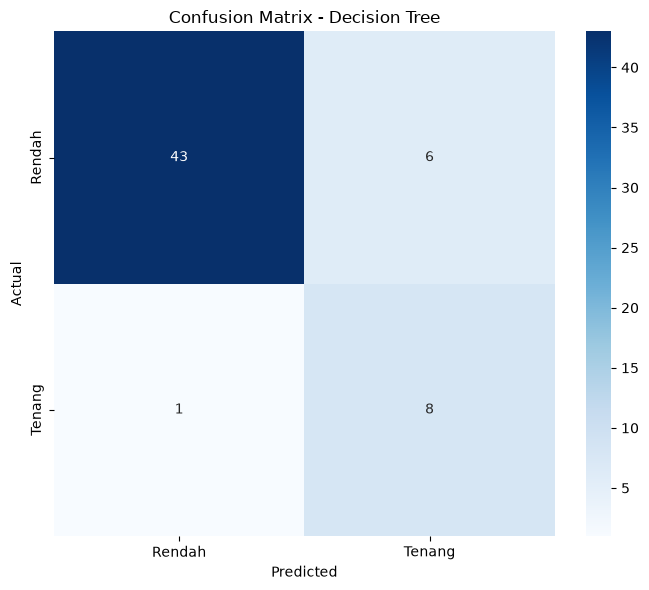


INSIGHT EVALUASI MODEL

Hasil evaluasi menunjukkan bahwa model Decision Tree memperoleh
accuracy sebesar 87.93% pada 58 data
testing. Dari seluruh data testing, sebanyak 51 data
berhasil diklasifikasikan dengan benar, sedangkan 7
data masih mengalami kesalahan klasifikasi.

Untuk kategori Rendah, model memperoleh precision sebesar
0.98, recall sebesar 0.88, dan
F1-score sebesar 0.92. Sementara itu, kategori Tenang
memperoleh precision sebesar 0.57, recall sebesar
0.89, dan F1-score sebesar 0.70.

Nilai macro F1-score sebesar 0.81 menunjukkan performa
rata-rata model pada kedua kategori dengan memberikan bobot yang
sama terhadap setiap kategori. Weighted F1-score sebesar
0.89 menunjukkan performa dengan mempertimbangkan
jumlah data pada masing-masing kategori.

Berdasarkan confusion matrix:
- Data Rendah yang diprediksi Rendah: 43
- Data Rendah yang diprediksi Tenang: 6
- Data Tenang yang diprediksi Rendah: 1
- Data Tenang yang diprediksi Tenang: 8

Hasil tersebut menunjukkan bahwa mod

In [201]:
# ============================================================
# 17. EVALUASI MODEL
# ============================================================

print("\n" + "=" * 80)
print("EVALUASI MODEL")
print("=" * 80)


# ------------------------------------------------------------
# ACCURACY
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    f"\nAccuracy: {accuracy:.4f}"
)

print(
    f"Accuracy: {accuracy * 100:.2f}%"
)


# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n--- CLASSIFICATION REPORT ---")

print(
    classification_report(
        y_test,
        y_pred
    )
)


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\n--- CONFUSION MATRIX ---")

print(cm)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title(
    "Confusion Matrix - Decision Tree"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.tight_layout()

plt.savefig(
    "17_confusion_matrix_decision_tree.png",
    dpi=300
)

plt.show()

# ============================================================
# INSIGHT EVALUASI MODEL
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT EVALUASI MODEL")
print("=" * 80)

# ------------------------------------------------------------
# DATA OTOMATIS DARI HASIL EVALUASI
# ------------------------------------------------------------

jumlah_testing = len(y_test)
jumlah_benar = (y_test == y_pred).sum()
jumlah_salah = jumlah_testing - jumlah_benar

# classification report dalam bentuk dictionary
report = classification_report(
    y_test,
    y_pred,
    output_dict=True
)

# Ambil metrik berdasarkan nama kelas
precision_rendah = report.get("Rendah", {}).get("precision", 0)
recall_rendah = report.get("Rendah", {}).get("recall", 0)
f1_rendah = report.get("Rendah", {}).get("f1-score", 0)

precision_tenang = report.get("Tenang", {}).get("precision", 0)
recall_tenang = report.get("Tenang", {}).get("recall", 0)
f1_tenang = report.get("Tenang", {}).get("f1-score", 0)

macro_f1 = report.get("macro avg", {}).get("f1-score", 0)
weighted_f1 = report.get("weighted avg", {}).get("f1-score", 0)

# Confusion matrix
kelas = list(model.classes_)

cm_dict = {
    kelas[i]: {
        kelas[j]: cm[i, j]
        for j in range(len(kelas))
    }
    for i in range(len(kelas))
}

# ------------------------------------------------------------
# INSIGHT
# ------------------------------------------------------------

print(f"""
Hasil evaluasi menunjukkan bahwa model Decision Tree memperoleh
accuracy sebesar {accuracy * 100:.2f}% pada {jumlah_testing:,} data
testing. Dari seluruh data testing, sebanyak {jumlah_benar:,} data
berhasil diklasifikasikan dengan benar, sedangkan {jumlah_salah:,}
data masih mengalami kesalahan klasifikasi.

Untuk kategori Rendah, model memperoleh precision sebesar
{precision_rendah:.2f}, recall sebesar {recall_rendah:.2f}, dan
F1-score sebesar {f1_rendah:.2f}. Sementara itu, kategori Tenang
memperoleh precision sebesar {precision_tenang:.2f}, recall sebesar
{recall_tenang:.2f}, dan F1-score sebesar {f1_tenang:.2f}.

Nilai macro F1-score sebesar {macro_f1:.2f} menunjukkan performa
rata-rata model pada kedua kategori dengan memberikan bobot yang
sama terhadap setiap kategori. Weighted F1-score sebesar
{weighted_f1:.2f} menunjukkan performa dengan mempertimbangkan
jumlah data pada masing-masing kategori.

Berdasarkan confusion matrix:
- Data Rendah yang diprediksi Rendah: {cm_dict.get("Rendah", {}).get("Rendah", 0)}
- Data Rendah yang diprediksi Tenang: {cm_dict.get("Rendah", {}).get("Tenang", 0)}
- Data Tenang yang diprediksi Rendah: {cm_dict.get("Tenang", {}).get("Rendah", 0)}
- Data Tenang yang diprediksi Tenang: {cm_dict.get("Tenang", {}).get("Tenang", 0)}

Hasil tersebut menunjukkan bahwa model masih memiliki kesalahan
dalam membedakan kategori Rendah dan Tenang. Perbandingan precision,
recall, dan F1-score pada kedua kategori digunakan untuk melihat
kemampuan model secara lebih menyeluruh, terutama karena distribusi
data antar kategori tidak seimbang.
""")

In [202]:
# ============================================================
# 18. CROSS VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("5-FOLD CROSS VALIDATION")
print("=" * 80)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("\nAccuracy setiap fold:")

for nomor, skor in enumerate(
    cv_scores,
    start=1
):

    print(
        f"Fold {nomor}: {skor:.4f}"
    )


print(
    f"\nRata-rata accuracy: "
    f"{cv_scores.mean():.4f}"
)

print(
    f"Standar deviasi: "
    f"{cv_scores.std():.4f}"
)

# ============================================================
# INSIGHT 5-FOLD CROSS VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT 5-FOLD CROSS VALIDATION")
print("=" * 80)

rata_rata_cv = cv_scores.mean()
standar_deviasi_cv = cv_scores.std()

fold_tertinggi = cv_scores.max()
fold_terendah = cv_scores.min()

fold_tertinggi_nomor = cv_scores.argmax() + 1
fold_terendah_nomor = cv_scores.argmin() + 1

print(f"""
Hasil 5-Fold Cross Validation menunjukkan bahwa model Decision Tree
memperoleh rata-rata accuracy sebesar {rata_rata_cv * 100:.2f}% dengan
standar deviasi sebesar {standar_deviasi_cv * 100:.2f}%.

Accuracy tertinggi diperoleh pada Fold {fold_tertinggi_nomor} sebesar
{fold_tertinggi * 100:.2f}%, sedangkan accuracy terendah diperoleh
pada Fold {fold_terendah_nomor} sebesar {fold_terendah * 100:.2f}%.

Rentang accuracy antar-fold adalah {fold_terendah * 100:.2f}% hingga
{fold_tertinggi * 100:.2f}%. Perbedaan nilai accuracy tersebut
menunjukkan adanya variasi performa model ketika data dibagi ke
dalam subset training dan testing yang berbeda.

Standar deviasi sebesar {standar_deviasi_cv * 100:.2f}% menunjukkan
tingkat variasi performa model antar-fold. Semakin kecil standar
deviasi, semakin konsisten performa model pada pembagian data yang
berbeda.
""")



5-FOLD CROSS VALIDATION

Accuracy setiap fold:
Fold 1: 0.8448
Fold 2: 0.8103
Fold 3: 0.7018
Fold 4: 0.7368
Fold 5: 0.7719

Rata-rata accuracy: 0.7731
Standar deviasi: 0.0509

INSIGHT 5-FOLD CROSS VALIDATION

Hasil 5-Fold Cross Validation menunjukkan bahwa model Decision Tree
memperoleh rata-rata accuracy sebesar 77.31% dengan
standar deviasi sebesar 5.09%.

Accuracy tertinggi diperoleh pada Fold 1 sebesar
84.48%, sedangkan accuracy terendah diperoleh
pada Fold 3 sebesar 70.18%.

Rentang accuracy antar-fold adalah 70.18% hingga
84.48%. Perbedaan nilai accuracy tersebut
menunjukkan adanya variasi performa model ketika data dibagi ke
dalam subset training dan testing yang berbeda.

Standar deviasi sebesar 5.09% menunjukkan
tingkat variasi performa model antar-fold. Semakin kecil standar
deviasi, semakin konsisten performa model pada pembagian data yang
berbeda.



In [203]:
# ============================================================
# 19. FEATURE IMPORTANCE
# ============================================================

print("\n" + "=" * 80)
print("FEATURE IMPORTANCE")
print("=" * 80)

classifier = model.named_steps[
    "classifier"
]

importance = classifier.feature_importances_

feature_importance = pd.DataFrame({

    "feature": fitur,

    "importance": importance

}).sort_values(
    by="importance",
    ascending=False
)


print(
    feature_importance.to_string(
        index=False
    )
)

# ============================================================
# INSIGHT FEATURE IMPORTANCE
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT FEATURE IMPORTANCE")
print("=" * 80)

fitur_teratas = feature_importance.iloc[0]["feature"]
importance_teratas = feature_importance.iloc[0]["importance"]

fitur_kedua = feature_importance.iloc[1]["feature"]
importance_kedua = feature_importance.iloc[1]["importance"]

fitur_ketiga = feature_importance.iloc[2]["feature"]
importance_ketiga = feature_importance.iloc[2]["importance"]

jumlah_fitur_nol = (
    feature_importance["importance"] == 0
).sum()

print(f"""
Hasil feature importance menunjukkan bahwa fitur yang paling banyak
digunakan oleh Decision Tree dalam membentuk keputusan klasifikasi
adalah {fitur_teratas} dengan nilai importance sebesar
{importance_teratas:.3f}. Fitur berikutnya adalah {fitur_kedua}
sebesar {importance_kedua:.3f}, kemudian {fitur_ketiga} sebesar
{importance_ketiga:.3f}.

Secara keseluruhan, terdapat {jumlah_fitur_nol} fitur yang memiliki
nilai importance sebesar 0 pada model. Hal ini menunjukkan bahwa
fitur tersebut tidak digunakan dalam pembentukan keputusan pada
pohon Decision Tree yang dihasilkan.

Fitur dengan nilai importance yang lebih tinggi memberikan kontribusi
yang lebih besar terhadap keputusan model dibandingkan fitur dengan
nilai importance yang lebih rendah. Namun, feature importance hanya
menunjukkan kontribusi fitur dalam pembentukan keputusan model dan
tidak dapat digunakan untuk menyimpulkan hubungan sebab-akibat.
""")


FEATURE IMPORTANCE
                feature  importance
          current_speed    0.413830
               latitude    0.198625
             wind_speed    0.173369
     jumlah_gempa_24jam    0.166117
               humidity    0.048059
              longitude    0.000000
            temperature    0.000000
              wind_gust    0.000000
   magnitude_maks_24jam    0.000000
jarak_gempa_terdekat_km    0.000000

INSIGHT FEATURE IMPORTANCE

Hasil feature importance menunjukkan bahwa fitur yang paling banyak
digunakan oleh Decision Tree dalam membentuk keputusan klasifikasi
adalah current_speed dengan nilai importance sebesar
0.414. Fitur berikutnya adalah latitude
sebesar 0.199, kemudian wind_speed sebesar
0.173.

Secara keseluruhan, terdapat 5 fitur yang memiliki
nilai importance sebesar 0 pada model. Hal ini menunjukkan bahwa
fitur tersebut tidak digunakan dalam pembentukan keputusan pada
pohon Decision Tree yang dihasilkan.

Fitur dengan nilai importance yang lebih tinggi memberikan

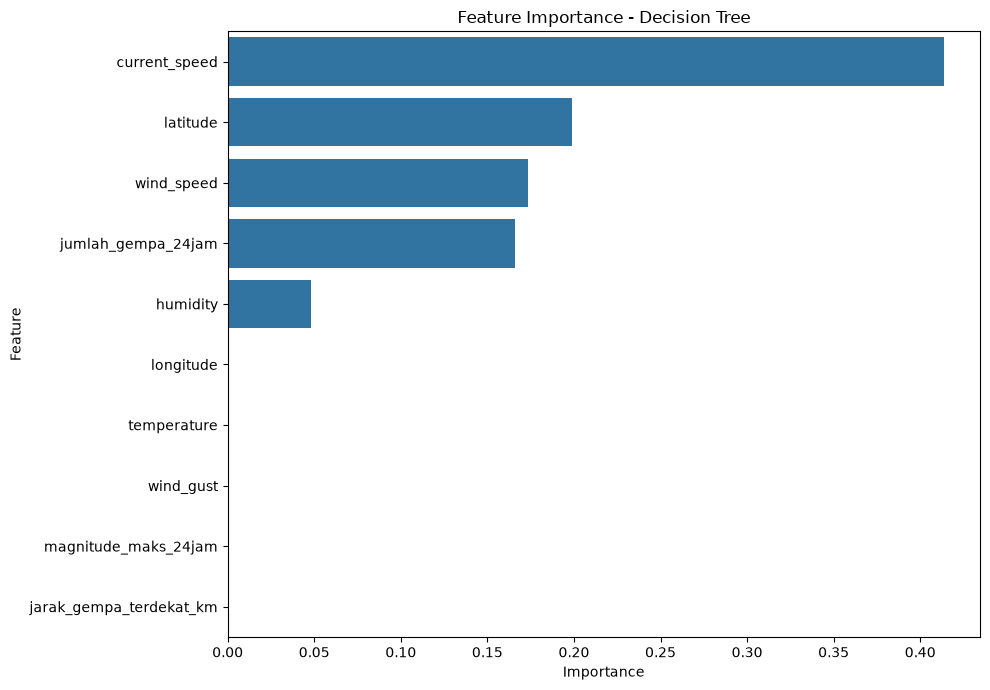

In [204]:
# ------------------------------------------------------------
# VISUAL 18
# FEATURE IMPORTANCE
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 7)
)

sns.barplot(
    data=feature_importance,
    x="importance",
    y="feature"
)

plt.title(
    "Feature Importance - Decision Tree"
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.savefig(
    "18_feature_importance_decision_tree.png",
    dpi=300
)

plt.show()


VISUALISASI DECISION TREE


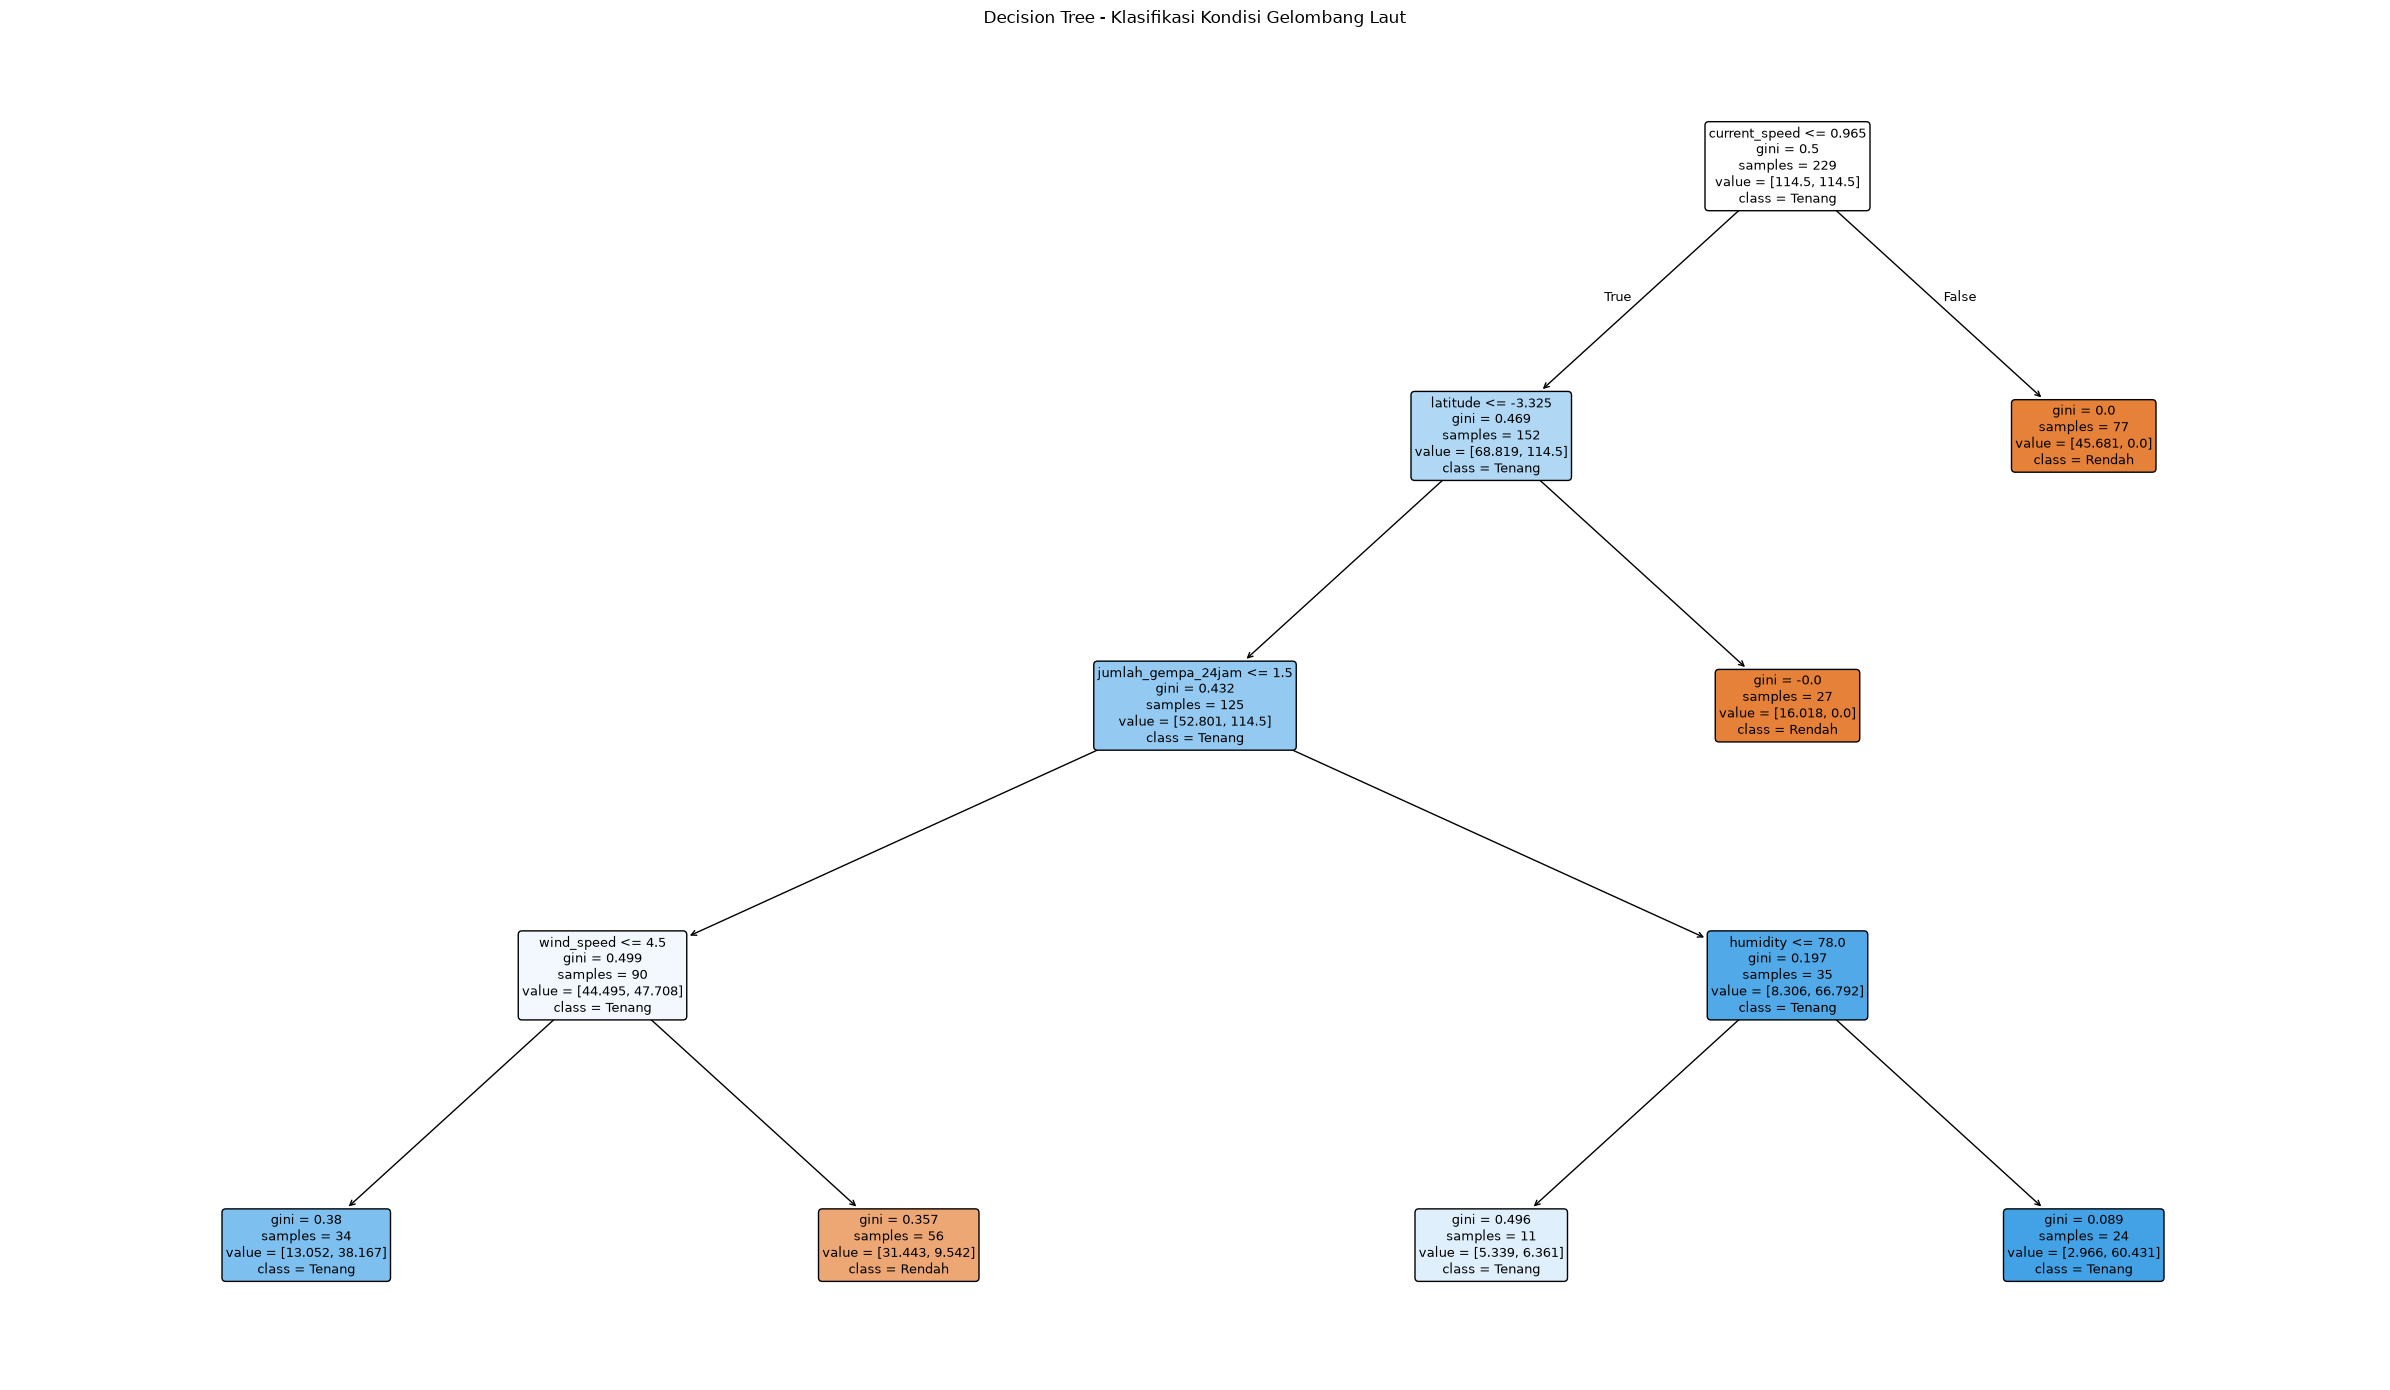

In [205]:
# ============================================================
# 21. VISUALISASI POHON KEPUTUSAN
# ============================================================

print("\n" + "=" * 80)
print("VISUALISASI DECISION TREE")
print("=" * 80)

plt.figure(
    figsize=(24, 14)
)

plot_tree(

    classifier,

    feature_names=fitur,

    class_names=classifier.classes_,

    filled=True,

    rounded=True,

    fontsize=9
)

plt.title(
    "Decision Tree - Klasifikasi Kondisi Gelombang Laut"
)

plt.tight_layout()

plt.savefig(
    "19_visualisasi_decision_tree.png",
    dpi=300
)

plt.show()

In [206]:
# ============================================================
# 22. INFORMASI STRUKTUR DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("INFORMASI DECISION TREE")
print("=" * 80)

print(
    "Max depth:",
    classifier.max_depth
)

print(
    "Actual tree depth:",
    classifier.tree_.max_depth
)

print(
    "Jumlah leaves:",
    classifier.get_n_leaves()
)

# ============================================================
# INSIGHT INFORMASI DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT INFORMASI DECISION TREE")
print("=" * 80)

max_depth = classifier.max_depth
actual_depth = classifier.tree_.max_depth
jumlah_leaves = classifier.get_n_leaves()

print(f"""
Decision Tree yang dibangun memiliki batas kedalaman maksimum
sebesar {max_depth}, sedangkan kedalaman aktual pohon yang terbentuk
adalah {actual_depth}. Model memiliki total {jumlah_leaves} leaf atau
daun keputusan.

Kedalaman aktual menunjukkan jumlah tingkat pemisahan yang digunakan
model dalam membentuk keputusan klasifikasi. Sementara itu, jumlah
leaf menunjukkan banyaknya hasil akhir keputusan yang terbentuk
dalam struktur pohon.

Batas kedalaman maksimum sebesar {max_depth} digunakan untuk
membatasi kompleksitas model agar pohon tidak berkembang terlalu
dalam. Struktur dengan {jumlah_leaves} leaf menunjukkan bahwa model
membentuk beberapa aturan keputusan untuk membedakan kategori
Tenang dan Rendah berdasarkan fitur yang digunakan.
""")


INFORMASI DECISION TREE
Max depth: 4
Actual tree depth: 4
Jumlah leaves: 6

INSIGHT INFORMASI DECISION TREE

Decision Tree yang dibangun memiliki batas kedalaman maksimum
sebesar 4, sedangkan kedalaman aktual pohon yang terbentuk
adalah 4. Model memiliki total 6 leaf atau
daun keputusan.

Kedalaman aktual menunjukkan jumlah tingkat pemisahan yang digunakan
model dalam membentuk keputusan klasifikasi. Sementara itu, jumlah
leaf menunjukkan banyaknya hasil akhir keputusan yang terbentuk
dalam struktur pohon.

Batas kedalaman maksimum sebesar 4 digunakan untuk
membatasi kompleksitas model agar pohon tidak berkembang terlalu
dalam. Struktur dengan 6 leaf menunjukkan bahwa model
membentuk beberapa aturan keputusan untuk membedakan kategori
Tenang dan Rendah berdasarkan fitur yang digunakan.



In [207]:
# ============================================================
# 23. CONTOH HASIL PREDIKSI
# ============================================================

print("\n" + "=" * 80)
print("CONTOH HASIL PREDIKSI")
print("=" * 80)

hasil_prediksi = X_test.copy()

hasil_prediksi["aktual"] = y_test.values
hasil_prediksi["prediksi"] = y_pred

contoh = hasil_prediksi.head(10)

print(
    contoh.to_string()
)


# ============================================================
# INSIGHT CONTOH HASIL PREDIKSI
# ============================================================

print("\n" + "=" * 80)
print("INSIGHT CONTOH HASIL PREDIKSI")
print("=" * 80)

jumlah_contoh = len(contoh)

jumlah_benar = (
    contoh["aktual"] == contoh["prediksi"]
).sum()

jumlah_salah = jumlah_contoh - jumlah_benar

akurasi_contoh = (
    jumlah_benar / jumlah_contoh * 100
)

distribusi_aktual = contoh["aktual"].value_counts()
distribusi_prediksi = contoh["prediksi"].value_counts()

print(f"""
Contoh hasil prediksi menampilkan {jumlah_contoh} data dari data
testing beserta kategori aktual dan hasil prediksi model.

Dari {jumlah_contoh} contoh data tersebut, sebanyak {jumlah_benar}
data berhasil diprediksi sesuai dengan kategori aktual, sedangkan
{jumlah_salah} data tidak sesuai. Dengan demikian, tingkat ketepatan
pada contoh data yang ditampilkan adalah {akurasi_contoh:.2f}%.

Distribusi kategori aktual pada contoh data:
{distribusi_aktual.to_string()}

Distribusi kategori hasil prediksi:
{distribusi_prediksi.to_string()}

Hasil ini memberikan gambaran langsung mengenai kemampuan model
dalam membedakan kategori Tenang dan Rendah. Namun, hasil dari
10 contoh data ini bukan merupakan ukuran performa keseluruhan
model. Penilaian performa model tetap mengacu pada hasil evaluasi
menggunakan seluruh data testing.
""")


CONTOH HASIL PREDIKSI
     latitude  longitude  temperature  humidity  wind_speed  wind_gust  current_speed  jumlah_gempa_24jam  magnitude_maks_24jam  jarak_gempa_terdekat_km  aktual prediksi
233     -4.00     122.65         26.0      76.0         2.0       14.0           0.79                   0                   0.0              9999.000000  Tenang   Tenang
127     -3.25     122.60         26.0      81.0         6.0       15.0           0.86                   1                   3.1               143.960281  Rendah   Rendah
250     -3.45     121.75         28.0      73.0         7.0       18.0           0.95                   0                   0.0              9999.000000  Rendah   Rendah
222     -3.45     121.75         27.0      80.0         4.0       12.0           0.94                   0                   0.0              9999.000000  Rendah   Tenang
0       -3.40     122.45         26.0      84.0         2.0        9.0           0.67                   3                   4.5

In [213]:
import os

os.makedirs("hasil", exist_ok=True)

In [214]:
# ============================================================
# 24. SIMPAN HASIL PREDIKSI
# ============================================================

hasil_prediksi.to_csv(
    "hasil/hasil_prediksi_klasifikasi.csv",
    index=False
)

print(
    "\nFile hasil_prediksi_klasifikasi.csv berhasil disimpan di folder ml/hasil/."
)


File hasil_prediksi_klasifikasi.csv berhasil disimpan di folder ml/hasil/.


In [209]:
# ============================================================
# 25. RINGKASAN HASIL
# ============================================================

print("\n" + "=" * 80)
print("RINGKASAN HASIL PROYEK")
print("=" * 80)

print(
    f"\nJumlah data akhir       : {len(df)}"
)

print(
    f"Jumlah fitur ML         : {len(fitur)}"
)

print(
    f"Jumlah data training    : {len(X_train)}"
)

print(
    f"Jumlah data testing     : {len(X_test)}"
)

print(
    f"Accuracy Decision Tree  : {accuracy * 100:.2f}%"
)

print(
    f"CV Mean Accuracy        : {cv_scores.mean() * 100:.2f}%"
)

print(
    f"CV Std                  : {cv_scores.std():.4f}"
)

print("\nFeature paling berpengaruh:")

print(
    feature_importance.head(5).to_string(
        index=False
    )
)




RINGKASAN HASIL PROYEK

Jumlah data akhir       : 287
Jumlah fitur ML         : 10
Jumlah data training    : 229
Jumlah data testing     : 58
Accuracy Decision Tree  : 87.93%
CV Mean Accuracy        : 77.31%
CV Std                  : 0.0509

Feature paling berpengaruh:
           feature  importance
     current_speed    0.413830
          latitude    0.198625
        wind_speed    0.173369
jumlah_gempa_24jam    0.166117
          humidity    0.048059


In [210]:
# ============================================================
# SELESAI
# ============================================================

print("\n" + "=" * 80)
print("SELURUH PROSES SELESAI")
print("=" * 80)

print("""
VISUALISASI YANG DIHASILKAN:

BQ1 - Kondisi Gelombang per Wilayah
1.  bq1_01_jumlah_kategori_per_wilayah.png
2.  bq1_02_proporsi_kategori_per_wilayah.png
3.  bq1_03_boxplot_tinggi_gelombang_wilayah.png
4.  bq1_04_boxplot_angin_wilayah.png

BQ2 - Hubungan Faktor Cuaca dan Kondisi Laut
5.  bq2_05_scatter_angin_vs_gelombang.png
6.  bq2_06_scatter_arus_vs_gelombang.png
7.  bq2_07_scatter_angin_vs_arus.png
8.  bq2_08_correlation_heatmap.png
9.  bq2_09_boxplot_angin_kategori.png
10. bq2_10_boxplot_arus_kategori.png
11. bq2_11_boxplot_temperature_kategori.png
12. bq2_12_boxplot_humidity_kategori.png

BQ3 - Lokasi dan Waktu
13. bq3_13_spatial_gelombang.png
14. bq3_14_temporal_tinggi_gelombang.png
15. bq3_15_temporal_kategori_gelombang.png
16. bq3_16_heatmap_wilayah_waktu.png

Machine Learning
17. 17_confusion_matrix_decision_tree.png
18. 18_feature_importance_decision_tree.png
19. 19_visualisasi_decision_tree.png

Output
20. hasil_prediksi_klasifikasi.csv
""")

print("=" * 80)


SELURUH PROSES SELESAI

VISUALISASI YANG DIHASILKAN:

BQ1 - Kondisi Gelombang per Wilayah
1.  bq1_01_jumlah_kategori_per_wilayah.png
2.  bq1_02_proporsi_kategori_per_wilayah.png
3.  bq1_03_boxplot_tinggi_gelombang_wilayah.png
4.  bq1_04_boxplot_angin_wilayah.png

BQ2 - Hubungan Faktor Cuaca dan Kondisi Laut
5.  bq2_05_scatter_angin_vs_gelombang.png
6.  bq2_06_scatter_arus_vs_gelombang.png
7.  bq2_07_scatter_angin_vs_arus.png
8.  bq2_08_correlation_heatmap.png
9.  bq2_09_boxplot_angin_kategori.png
10. bq2_10_boxplot_arus_kategori.png
11. bq2_11_boxplot_temperature_kategori.png
12. bq2_12_boxplot_humidity_kategori.png

BQ3 - Lokasi dan Waktu
13. bq3_13_spatial_gelombang.png
14. bq3_14_temporal_tinggi_gelombang.png
15. bq3_15_temporal_kategori_gelombang.png
16. bq3_16_heatmap_wilayah_waktu.png

Machine Learning
17. 17_confusion_matrix_decision_tree.png
18. 18_feature_importance_decision_tree.png
19. 19_visualisasi_decision_tree.png

Output
20. hasil_prediksi_klasifikasi.csv



In [211]:
# ============================================================
# 25. KESIMPULAN
# ============================================================

print("\n" + "=" * 80)
print("25. KESIMPULAN")
print("=" * 80)

# ------------------------------------------------------------
# DATA OTOMATIS
# ------------------------------------------------------------

jumlah_data = len(df)
jumlah_fitur = len(fitur)

distribusi_target = y.value_counts()

kategori_dominan = distribusi_target.idxmax()
jumlah_dominan = distribusi_target.max()
proporsi_dominan = jumlah_dominan / jumlah_data * 100

akurasi_model = accuracy

rata_rata_cv = cv_scores.mean()
std_cv = cv_scores.std()

fitur_teratas = feature_importance.iloc[0]["feature"]
importance_teratas = feature_importance.iloc[0]["importance"]

actual_depth = classifier.tree_.max_depth
jumlah_leaves = classifier.get_n_leaves()

# ------------------------------------------------------------
# KESIMPULAN OTOMATIS
# ------------------------------------------------------------

print(f"""
Berdasarkan seluruh proses pengolahan dan analisis data, dapat
disimpulkan bahwa dataset yang digunakan memiliki {jumlah_data:,}
data dengan {jumlah_fitur} fitur yang mencakup informasi lokasi,
cuaca, kondisi laut, dan aktivitas gempa.

Hasil Exploratory Data Analysis (EDA) menunjukkan bahwa kondisi
gelombang laut memiliki variasi berdasarkan wilayah perairan dan
waktu pengamatan. Perbedaan kondisi juga dapat diamati melalui
hubungan antara variabel cuaca dan kondisi laut terhadap kategori
gelombang.

Pada tahap klasifikasi, Decision Tree digunakan untuk memprediksi
dua kategori kondisi gelombang, yaitu Tenang dan Rendah. Kategori
{kategori_dominan} merupakan kategori yang paling dominan dengan
jumlah {jumlah_dominan:,} data atau {proporsi_dominan:.2f}% dari
seluruh dataset.

Hasil evaluasi pada data testing menunjukkan bahwa model memperoleh
accuracy sebesar {akurasi_model * 100:.2f}%. Sementara itu, hasil
5-Fold Cross Validation menghasilkan rata-rata accuracy sebesar
{rata_rata_cv * 100:.2f}% dengan standar deviasi sebesar
{std_cv * 100:.2f}%. Hasil tersebut menunjukkan kemampuan model
dalam melakukan klasifikasi pada data yang belum digunakan selama
proses pelatihan serta memberikan gambaran mengenai konsistensi
performa model pada beberapa pembagian data.

Berdasarkan feature importance, fitur yang paling banyak digunakan
oleh Decision Tree adalah {fitur_teratas} dengan nilai importance
sebesar {importance_teratas:.3f}. Namun, nilai tersebut menunjukkan
kontribusi fitur terhadap keputusan model dan tidak dapat diartikan
sebagai hubungan sebab-akibat.

Struktur Decision Tree memiliki kedalaman aktual sebesar
{actual_depth} dengan {jumlah_leaves} leaf. Struktur tersebut
menunjukkan bahwa model membentuk beberapa aturan keputusan untuk
membedakan kategori Tenang dan Rendah dengan kompleksitas yang
dibatasi.

Dengan demikian, Decision Tree dapat digunakan sebagai pendekatan
untuk mengklasifikasikan kondisi gelombang laut berdasarkan faktor
lokasi, cuaca, kondisi laut, dan aktivitas gempa yang tersedia pada
dataset. Hasil model tetap perlu dipahami berdasarkan distribusi
data dan hasil evaluasi, sehingga accuracy, performa masing-masing
kategori, serta konsistensi cross-validation perlu dipertimbangkan
secara bersama-sama.
""")


25. KESIMPULAN

Berdasarkan seluruh proses pengolahan dan analisis data, dapat
disimpulkan bahwa dataset yang digunakan memiliki 287
data dengan 10 fitur yang mencakup informasi lokasi,
cuaca, kondisi laut, dan aktivitas gempa.

Hasil Exploratory Data Analysis (EDA) menunjukkan bahwa kondisi
gelombang laut memiliki variasi berdasarkan wilayah perairan dan
waktu pengamatan. Perbedaan kondisi juga dapat diamati melalui
hubungan antara variabel cuaca dan kondisi laut terhadap kategori
gelombang.

Pada tahap klasifikasi, Decision Tree digunakan untuk memprediksi
dua kategori kondisi gelombang, yaitu Tenang dan Rendah. Kategori
Rendah merupakan kategori yang paling dominan dengan
jumlah 242 data atau 84.32% dari
seluruh dataset.

Hasil evaluasi pada data testing menunjukkan bahwa model memperoleh
accuracy sebesar 87.93%. Sementara itu, hasil
5-Fold Cross Validation menghasilkan rata-rata accuracy sebesar
77.31% dengan standar deviasi sebesar
5.09%. Hasil tersebut menunjukkan kemampuan mode